# RetailSense — AI-Powered Customer Experience Intelligence

**BC3415 Individual Assignment | Option A: Coding**

## Project overview
RetailSense analyses women's clothing customer reviews to identify sentiment, detect potential product-related complaints, prioritise follow-up and consolidate recurring customer concerns. The interactive React/FastAPI dashboard is deployed separately; this notebook documents the **Python model experiments, evaluation, reusable inference and operational-data export**.

**Pipeline:** Raw reviews → cleaning and sentiment labels → train/validation/test split → baseline and advanced sentiment classifiers → selected DistilBERT → hybrid issue-context detection → explainable triage → operational review predictions → deployed dashboard.

**Interpretation:** Model-identified issues and suggested actions are **preliminary signals, not verified defects**. The Render dashboard displays **precomputed historical predictions**; its server does **not** run the large NLP models in real time.

## Before running in Google Colab

1. Use a **GPU runtime** for transformer training and large-scale inference; the notebook is not intended to be fast on CPU.
2. Upload these three **input data files** to `/content/` (same filenames as used below):
   - `Womens Clothing E-Commerce Reviews.csv.zip` — original dataset archive containing one CSV
   - `retailsense_context_annotated_draft.csv` — human-reviewed issue-context development annotations
   - `retailsense_exploratory_labels.csv` — separate exploratory evaluation labels (**weak/automated**, not human-verified gold labels)
3. Allow downloads from Hugging Face when first loading DistilBERT, MPNet and BART-large-MNLI. The notebook creates `/content/retailsense_final_candidate/` after model training and `/content/retailsense_operational/` for operational predictions.
4. **Execute top-to-bottom on a clean runtime** for full reproduction. Do not skip training/checkpoint-producing cells unless the corresponding verified checkpoint and variables have been restored. The notebook's existing recorded results are historical outputs, **not proof of a successful fresh run**.
5. The 1,500-review operational set is disjoint from issue-detection development annotations, but is **not guaranteed to be disjoint from the sentiment classifier's earlier train/validation/test partitions**. It is a historical application demonstration, **not an independent held-out evaluation of sentiment performance**.

**Reproducibility note:** Colab package versions, network downloads and GPU availability can affect reruns. If runtime/dependency problems occur, document any environment adjustment and rerun affected cells. Preserve the held-out test evaluation and validation results separately from illustrative application metrics.

## Assessment evidence map

| Assessment focus | Notebook evidence |
|---|---|
| Data preparation | Section 1 — data quality, cleaning, EDA and leakage-aware splits |
| Model performance | Section 2 — baselines, comparisons, tuning, DistilBERT, BiLSTM, held-out test |
| Explainability and commentary | Sections 2–4 — confusion matrices, errors, context explanations, triage policy |
| Creative text insights | Sections 3–4 and 6 — issue contexts, complaint triage and recurring-concern inputs |
| Reusability and usability | Section 5 — `analyse_retailsense()`; Section 6 — verified operational export; GitHub/Render frontend |

---


## **1.1 Dataset Overview & Business Objectives**

**RetailSense: Data Understanding & Preprocessing**

RetailSense is an AI-powered retail customer feedback analysis system designed to transform unstructured product reviews into actionable business insights. The system aims to:

1. **Classify customer sentiment** as Positive, Neutral or Negative.
2. **Identify product-related complaints**, including defects, material quality, sizing issues and misdeliveries.
3. **Flag potentially problematic reviews** for investigation by retail operations teams.

This project uses the **Women’s Clothing E-Commerce Reviews** dataset to develop and evaluate text classification approaches. As the dataset contains review text but no verified defective-order labels, the system will identify potentially problematic reviews rather than confirm actual order defects.

This section establishes a reproducible data preparation pipeline to support reliable model training, fair evaluation and subsequent integration into the RetailSense application.

In [1]:
# Load Dataset


import io
import zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

RANDOM_STATE = 42
ZIP_PATH = Path("/content/Womens Clothing E-Commerce Reviews.csv.zip")

def load_review_data(zip_path):
    """Load the reviews CSV directly from a ZIP archive."""
    with zipfile.ZipFile(zip_path) as archive:
        csv_files = [
            name for name in archive.namelist()
            if name.lower().endswith(".csv")
        ]
        if len(csv_files) != 1:
            raise ValueError("Expected exactly one CSV file in the archive.")

        with archive.open(csv_files[0]) as file:
            return pd.read_csv(file)

df_raw = load_review_data(ZIP_PATH)

print(f"Dataset dimensions: {df_raw.shape[0]:,} rows × {df_raw.shape[1]} columns")
display(df_raw.head(5))


Dataset dimensions: 23,486 rows × 11 columns


,Unnamed: 0,Clothing ID,Age,Title,Review Text,Rating,Recommended IND,Positive Feedback Count,Division Name,Department Name,Class Name
0,0,767,33,NaN,Absolutely wonderful - silky and sexy and comf...,4,1,0,Initmates,Intimate,Intimates
1,1,1080,34,NaN,Love this dress! it's sooo pretty. i happene...,5,1,4,General,Dresses,Dresses
2,2,1077,60,Some major design flaws,I had such high hopes for this dress and reall...,3,0,0,General,Dresses,Dresses
3,3,1049,50,My favorite buy!,"I love, love, love this jumpsuit. it's fun, fl...",5,1,0,General Petite,Bottoms,Pants
4,4,847,47,Flattering shirt,This shirt is very flattering to all due to th...,5,1,6,General,Tops,Blouses


**Initial Dataset Overview**

The dataset contains **23,486 customer reviews and 11 columns**, covering review text, titles, star ratings, product categories and customer-related attributes.

For sentiment classification, the primary input will be the review text and, where available, its title. Star ratings will be used to construct reference sentiment labels, while product-category information can support downstream retail analytics.

Fields such as recommendation indicators and positive feedback counts will not be used as sentiment-model inputs, avoiding reliance on signals that may be unavailable or inappropriate when predicting sentiment from new review text.

## **1.2 Data Quality Assessment**

Before preprocessing, we examine missing values, data types and duplicate records to identify potential quality issues.

Particular attention is given to missing review text, since reviews without textual content cannot contribute to the text classification task. Missing titles and product-category information are treated separately, as they may still provide useful information without requiring the entire review to be discarded.

In [2]:

# Summarise data types, missing values and missing percentages
quality_report = pd.DataFrame({
    "Data Type": df_raw.dtypes.astype(str),
    "Missing Count": df_raw.isna().sum(),
    "Missing (%)": df_raw.isna().mean().mul(100).round(2)
})

display(quality_report)

# Examine missing or blank review text
missing_text = (
    df_raw["Review Text"].isna()
    | df_raw["Review Text"].fillna("").str.strip().eq("")
)

print(f"Reviews with missing/blank text: {missing_text.sum():,}")
print(f"Exact duplicate non-null review texts: "
      f"{df_raw['Review Text'].dropna().duplicated().sum():,}")

print("\nRating distribution:")
display(df_raw["Rating"].value_counts().sort_index())


,Data Type,Missing Count,Missing (%)
Unnamed: 0,int64,0,0.00
Clothing ID,int64,0,0.00
Age,int64,0,0.00
Title,object,3810,16.22
Review Text,object,845,3.60
Rating,int64,0,0.00
Recommended IND,int64,0,0.00
Positive Feedback Count,int64,0,0.00
Division Name,object,14,0.06
Department Name,object,14,0.06


Reviews with missing/blank text: 845
Exact duplicate non-null review texts: 7

Rating distribution:


,count
Rating,
1,842
2,1565
3,2871
4,5077
5,13131



**Data Quality Findings**

The initial assessment identified the following data quality issues:

| Data Quality Issue | Records Affected | Treatment |
|---|---:|---|
| Missing review text | 845 | Remove, as text is essential for classification |
| Missing review title | 3,810 | Retain review; replace missing title with an empty string |
| Missing product-category fields | 14 | Retain review; assign "Unknown" for analytics |
| Exact duplicate non-null review text | 7 | Remove duplicates to prevent data leakage |

**Preprocessing rationale:** Missing optional information does not necessarily make a review unusable. Therefore, the cleaning strategy preserves valid customer feedback while excluding records that cannot support text classification.

Exact duplicate review texts will also be removed to reduce the risk of identical content appearing across training, validation and test datasets.



## **1.3 Data Cleaning & Sentiment Labelling**

A reusable preprocessing function is implemented to standardise data preparation and ensure consistency across subsequent experiments.

The preprocessing pipeline performs four operations:

1. **Remove missing text:** Exclude records with missing or blank review text.
2. **Handle optional fields:** Standardise text whitespace and fill missing titles or product categories.
3. **Remove duplicates:** Eliminate exact duplicate review texts to reduce potential data leakage.
4. **Generate sentiment labels:** Derive three sentiment classes from customer star ratings.

**Sentiment Labelling Scheme**

| Star Rating | Sentiment |
|:---:|:---:|
| 1–2 | Negative |
| 3 | Neutral |
| 4–5 | Positive |

**Labelling limitation:** Star ratings are used as proxies for textual sentiment rather than independently annotated labels. A customer's written review may therefore express a sentiment that differs from their assigned rating.

**Preprocessing rationale:** Minimal text cleaning preserves sentiment-bearing expressions such as "not comfortable", which aggressive stopword removal could distort. Model-specific transformations, including TF-IDF vectorisation and transformer tokenisation, will be applied separately during model development.


In [3]:

SENTIMENT_MAP = {
    1: "Negative",
    2: "Negative",
    3: "Neutral",
    4: "Positive",
    5: "Positive"
}

CATEGORY_COLUMNS = [
    "Division Name",
    "Department Name",
    "Class Name"
]

def preprocess_reviews(df):
    """Clean review records and generate rating-derived sentiment labels."""
    data = df.copy()

    # Remove unnecessary index column
    data = data.drop(columns=["Unnamed: 0"], errors="ignore")

    # Validate required columns and star ratings
    required = {"Review Text", "Title", "Rating", *CATEGORY_COLUMNS}
    missing_columns = required - set(data.columns)

    if missing_columns:
        raise ValueError(f"Missing required columns: {missing_columns}")

    if not data["Rating"].isin(SENTIMENT_MAP).all():
        raise ValueError("Unexpected or missing star ratings detected.")

    # Remove reviews without usable text
    data = data.dropna(subset=["Review Text"]).copy()
    data["Review Text"] = data["Review Text"].str.strip()
    data = data[data["Review Text"].ne("")].copy()

    # Handle missing optional information
    data["Title"] = data["Title"].fillna("").str.strip()
    data[CATEGORY_COLUMNS] = data[CATEGORY_COLUMNS].fillna("Unknown")

    # Remove duplicate review text
    data = data.drop_duplicates(subset=["Review Text"]).copy()

    # Generate sentiment labels from ratings
    data["Sentiment"] = data["Rating"].map(SENTIMENT_MAP)

    return data.reset_index(drop=True)



# Track records removed at each preprocessing stage
missing_text = (
    df_raw["Review Text"].isna()
    | df_raw["Review Text"].fillna("").str.strip().eq("")
)

valid_text = df_raw.loc[~missing_text].copy()
duplicate_text = valid_text["Review Text"].str.strip().duplicated()

# Apply preprocessing
reviews = preprocess_reviews(df_raw)

# Summarise preprocessing results
cleaning_summary = pd.DataFrame({
    "Preprocessing Stage": [
        "Original dataset",
        "Missing/blank review text removed",
        "Duplicate review texts removed",
        "Final cleaned dataset"
    ],
    "Number of Reviews": [
        len(df_raw),
        int(missing_text.sum()),
        int(duplicate_text.sum()),
        len(reviews)
    ]
})

display(cleaning_summary)

# Verify that the removal counts reconcile
assert (
    len(df_raw)
    == missing_text.sum() + duplicate_text.sum() + len(reviews)
)

print("Preprocessing validation passed.")

display(reviews[[
    "Title", "Review Text", "Rating",
    "Sentiment", "Department Name"
]].head())



,Preprocessing Stage,Number of Reviews
0,Original dataset,23486
1,Missing/blank review text removed,845
2,Duplicate review texts removed,7
3,Final cleaned dataset,22634


Preprocessing validation passed.


,Title,Review Text,Rating,Sentiment,Department Name
0,,Absolutely wonderful - silky and sexy and comf...,4,Positive,Intimate
1,,Love this dress! it's sooo pretty. i happene...,5,Positive,Dresses
2,Some major design flaws,I had such high hopes for this dress and reall...,3,Neutral,Dresses
3,My favorite buy!,"I love, love, love this jumpsuit. it's fun, fl...",5,Positive,Bottoms
4,Flattering shirt,This shirt is very flattering to all due to th...,5,Positive,Tops



**Preprocessing Results**

After preprocessing, the dataset contains **22,634 usable reviews**, retaining approximately **96.4% of the original 23,486 records**.

A total of 852 records were removed:
- **845 reviews** with missing or blank review text.
- **7 reviews** with duplicate text.

Missing optional fields were handled without unnecessarily discarding valid customer feedback. Each retained review now contains usable text and a sentiment label.

**Key takeaway:** The reusable preprocessing function ensures consistent data preparation, while duplicate removal reduces the risk of identical reviews appearing across training and evaluation datasets.



## **1.4 Exploratory Data Analysis (EDA)**

Exploratory Data Analysis (EDA) examines patterns in customer reviews to inform model development and identify opportunities for retail insights.

The analysis focuses on three areas:

1. **Sentiment distribution:** Identify class imbalance and its implications for model evaluation.
2. **Review length:** Examine the amount of textual information available across sentiment classes.
3. **Department-level sentiment:** Compare customer satisfaction patterns across clothing departments.

These findings will guide model selection, preprocessing decisions and subsequent retail analytics.


,Review Count,Percentage (%)
Sentiment,,
Negative,2369,10.47
Neutral,2823,12.47
Positive,17442,77.06


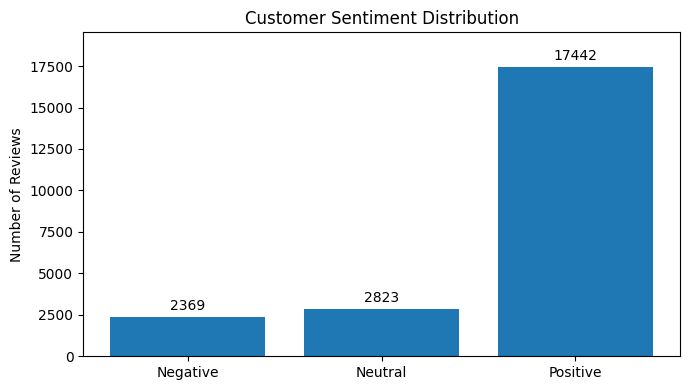

Review Length by Sentiment:


,count,median,mean
Sentiment,,,
Negative,2369,60.0,60.9
Neutral,2823,64.0,64.2
Positive,17442,58.0,59.5


Sentiment Distribution by Department (%):


Sentiment,Negative,Neutral,Positive
Department Name,,,
Bottoms,8.7,11.1,80.2
Dresses,11.1,13.5,75.4
Intimate,8.9,10.7,80.4
Jackets,10.8,9.0,80.2
Tops,10.9,12.9,76.1
Trend,17.8,16.1,66.1
Unknown,0.0,0.0,100.0


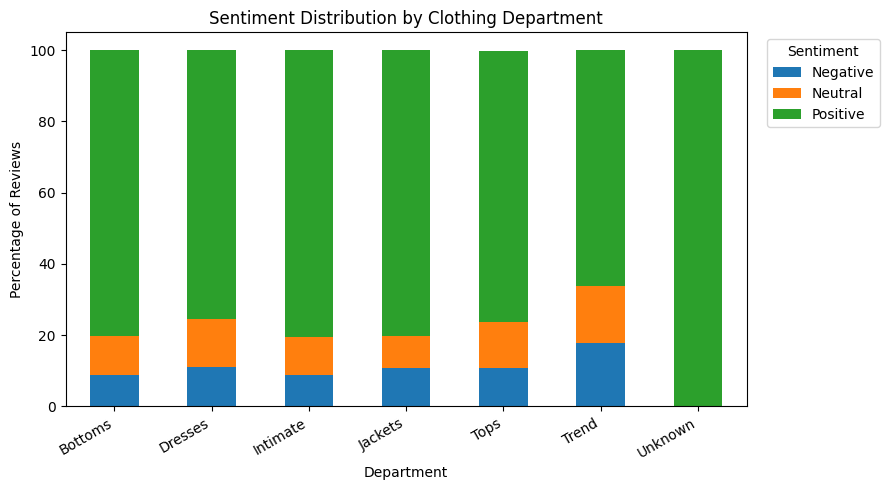

Sentiment,Total Reviews,Negative,Negative Rate (%)
Department Name,,,
Trend,118,21,17.80
Dresses,6144,680,11.07
Tops,10046,1096,10.91
Jackets,1002,108,10.78
Intimate,1650,147,8.91
Bottoms,3661,317,8.66
Unknown,13,0,0.00


In [4]:

import matplotlib.pyplot as plt

SENTIMENT_ORDER = ["Negative", "Neutral", "Positive"]

# 1. Sentiment distribution
sentiment_counts = (
    reviews["Sentiment"]
    .value_counts()
    .reindex(SENTIMENT_ORDER)
)

sentiment_summary = pd.DataFrame({
    "Review Count": sentiment_counts,
    "Percentage (%)": (
        sentiment_counts / len(reviews) * 100
    ).round(2)
})

display(sentiment_summary)

fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(sentiment_counts.index, sentiment_counts.values)

ax.bar_label(bars, padding=3)
ax.set_title("Customer Sentiment Distribution")
ax.set_ylabel("Number of Reviews")
ax.set_ylim(0, sentiment_counts.max() * 1.12)

plt.tight_layout()
plt.show()

# 2. Review length analysis
reviews["Review Word Count"] = (
    reviews["Review Text"].str.split().str.len()
)

length_summary = (
    reviews.groupby("Sentiment")["Review Word Count"]
    .agg(["count", "median", "mean"])
    .reindex(SENTIMENT_ORDER)
    .round(1)
)

print("Review Length by Sentiment:")
display(length_summary)

# 3. Sentiment distribution by clothing department
department_counts = pd.crosstab(
    reviews["Department Name"],
    reviews["Sentiment"]
).reindex(columns=SENTIMENT_ORDER, fill_value=0)

department_pct = (
    department_counts
    .div(department_counts.sum(axis=1), axis=0)
    .mul(100)
    .round(1)
)

print("Sentiment Distribution by Department (%):")
display(department_pct)

department_pct.plot(
    kind="bar",
    stacked=True,
    figsize=(9, 5)
)

plt.title("Sentiment Distribution by Clothing Department")
plt.xlabel("Department")
plt.ylabel("Percentage of Reviews")
plt.xticks(rotation=30, ha="right")
plt.legend(title="Sentiment", bbox_to_anchor=(1.02, 1))
plt.tight_layout()
plt.show()


# Assess department-level sample sizes and dissatisfaction
department_summary = department_counts.copy()

department_summary["Total Reviews"] = department_counts.sum(axis=1)
department_summary["Negative Rate (%)"] = (
    department_summary["Negative"]
    / department_summary["Total Reviews"] * 100
).round(2)

display(
    department_summary[
        ["Total Reviews", "Negative", "Negative Rate (%)"]
    ].sort_values("Negative Rate (%)", ascending=False)
)




**EDA Findings and Modelling Implications**

**1. Sentiment Class Imbalance**

Positive reviews dominate the dataset (**77.06%**), compared with Negative (**10.47%**) and Neutral (**12.47%**).

A majority-class classifier could achieve 77.06% accuracy by predicting every review as Positive, despite failing to identify customer dissatisfaction.

**Modelling implication:** Macro F1-score and class-specific precision/recall will complement accuracy. Negative recall is especially important for reducing overlooked dissatisfied customers.

**2. Review Length Analysis**

Review lengths are relatively consistent across sentiment classes:

| Sentiment | Median Words | Mean Words |
|---|---:|---:|
| Negative | 60 | 60.9 |
| Neutral | 64 | 64.2 |
| Positive | 58 | 59.5 |

Neutral reviews are slightly longer on average, although the differences are modest.

**Modelling implication:** Review length alone is unlikely to strongly distinguish sentiment classes. Models should focus on linguistic content and context.

**3. Department-Level Sentiment Analysis**

The **Trend** department has the highest negative review rate (**17.80%**), but this is based on only 118 reviews, limiting confidence in the estimate.

In contrast, **Tops (1,096)** and **Dresses (680)** account for approximately **75% of all negative reviews**, despite having lower negative rates of 10.91% and 11.07%, respectively.

**Business implication:** Retail managers should consider both complaint rates and volumes when prioritising investigations. Trend may warrant targeted monitoring, while Tops and Dresses offer greater opportunities for addressing dissatisfaction at scale.

Combining these sentiment patterns with product issue detection could subsequently reveal which departments experience more sizing, quality, defect or misdelivery complaints.

**Key Takeaway:** The EDA highlights significant class imbalance and demonstrates how combining sentiment rates with complaint volumes provides more actionable retail insights than sentiment classification alone.



## **1.5 Train, Validation & Test Split**

The cleaned dataset is divided into three mutually exclusive subsets to support reliable model development and evaluation.

| Dataset | Proportion | Purpose |
|---|---:|---|
| Training | 70% | Train models and fit text transformations |
| Validation | 15% | Compare models and optimise hyperparameters |
| Test | 15% | Evaluate the final selected model |

**Stratified sampling** preserves approximately the same sentiment proportions across all subsets, ensuring adequate representation of minority classes.

A fixed random seed ensures reproducibility, while deduplication before splitting prevents identical review texts from appearing across subsets.

**Data leakage prevention:** The test set will remain untouched during model selection and optimisation. Feature extraction techniques such as TF-IDF will be fitted exclusively on training data.


In [5]:

from sklearn.model_selection import train_test_split

RANDOM_STATE = 42

# Step 1: Reserve 15% for final testing
train_val_df, test_df = train_test_split(
    reviews,
    test_size=0.15,
    stratify=reviews["Sentiment"],
    random_state=RANDOM_STATE
)

# Step 2: Split remaining data into training and validation
# 0.15 / 0.85 allocates 15% of the full dataset to validation
train_df, val_df = train_test_split(
    train_val_df,
    test_size=0.15 / 0.85,
    stratify=train_val_df["Sentiment"],
    random_state=RANDOM_STATE
)

train_df = train_df.copy()
val_df = val_df.copy()
test_df = test_df.copy()

# Summarise dataset allocation
split_summary = pd.DataFrame({
    "Dataset": ["Training", "Validation", "Test"],
    "Review Count": [
        len(train_df), len(val_df), len(test_df)
    ]
})

split_summary["Percentage (%)"] = (
    split_summary["Review Count"] / len(reviews) * 100
).round(2)

print("Dataset Split Summary:")
display(split_summary)

# Verify sentiment proportions across subsets
sentiment_split = pd.DataFrame({
    "Training": train_df["Sentiment"].value_counts(normalize=True),
    "Validation": val_df["Sentiment"].value_counts(normalize=True),
    "Test": test_df["Sentiment"].value_counts(normalize=True)
}).reindex(["Negative", "Neutral", "Positive"]).mul(100).round(2)

print("Sentiment Distribution Across Splits (%):")
display(sentiment_split)

# Validate absence of identical review texts across subsets
train_texts = set(train_df["Review Text"])
val_texts = set(val_df["Review Text"])
test_texts = set(test_df["Review Text"])

assert train_texts.isdisjoint(val_texts)
assert train_texts.isdisjoint(test_texts)
assert val_texts.isdisjoint(test_texts)

# Verify all records are retained
assert len(train_df) + len(val_df) + len(test_df) == len(reviews)

print("All data integrity and leakage checks passed.")


Dataset Split Summary:


,Dataset,Review Count,Percentage (%)
0,Training,15843,70.0
1,Validation,3395,15.0
2,Test,3396,15.0


Sentiment Distribution Across Splits (%):


,Training,Validation,Test
Sentiment,,,
Negative,10.47,10.49,10.45
Neutral,12.47,12.46,12.49
Positive,77.06,77.05,77.06


All data integrity and leakage checks passed.



**Data Splitting and Leakage Prevention**

The cleaned dataset was successfully partitioned into:

| Dataset | Reviews | Proportion |
|---|---:|---:|
| Training | 15,843 | 70% |
| Validation | 3,395 | 15% |
| Test | 3,396 | 15% |

**Stratification validation:** Sentiment proportions remained consistent across all subsets, with Positive reviews representing approximately 77.06%, Negative reviews 10.47%, and Neutral reviews 12.47%.

All integrity checks passed, confirming that every cleaned review was allocated and no identical review texts appeared across different subsets.

**Evaluation implication:** Training and validation data will support model development and optimisation, while the test set will remain untouched until final evaluation. This enables more reliable comparisons across traditional machine learning, deep learning and transformer-based approaches.

**Limitation:** These checks prevent exact-text overlap but do not eliminate potential similarities between reviews of the same product or near-duplicate reviews.



## **1.6 Model Input Preparation & Validation**

A reusable input-preparation function is implemented to separate textual features (X) from sentiment labels (y), ensuring consistent inputs across model experiments.

**Feature selection:**
- **Review Text:** Primary input for sentiment classification.
- **Title:** Optional supplementary feature, whose contribution will be evaluated during model experimentation.
- **Sentiment:** Target label derived from customer star ratings.

Star ratings, recommendation indicators and other non-textual attributes are excluded from model inputs to prevent target leakage and ensure predictions rely on customer-written feedback.

**Model compatibility:** The same underlying review data will support traditional machine learning, deep learning and transformer-based models. Model-specific transformations, including TF-IDF vectorisation and tokenisation, will be applied separately using the training data.

This modular approach improves reproducibility, reusability and fairness across experiments.


In [6]:


TEXT_COLUMN = "Review Text"
TITLE_COLUMN = "Title"
TARGET_COLUMN = "Sentiment"

def prepare_model_inputs(data, include_title=False):
    """Prepare text features and sentiment labels for classification."""
    text = data[TEXT_COLUMN].fillna("").astype(str).str.strip()

    if include_title:
        title = data[TITLE_COLUMN].fillna("").astype(str).str.strip()
        text = title.where(title.eq(""), title + ". ") + text

    labels = data[TARGET_COLUMN].copy()

    return text, labels


# Prepare primary model inputs (review text only)
X_train, y_train = prepare_model_inputs(train_df)
X_val, y_val = prepare_model_inputs(val_df)

# Prepare alternative inputs (title + review text)
X_train_title, _ = prepare_model_inputs(
    train_df, include_title=True
)
X_val_title, _ = prepare_model_inputs(
    val_df, include_title=True
)

# Validate input consistency
assert len(X_train) == len(y_train)
assert len(X_val) == len(y_val)

assert X_train.notna().all()
assert X_val.notna().all()

assert set(y_train.unique()) == set(SENTIMENT_ORDER)
assert set(y_val.unique()) == set(SENTIMENT_ORDER)

# Verify that optional titles do not change the targets
assert len(X_train_title) == len(X_train)
assert len(X_val_title) == len(X_val)

print("Model input validation passed.")
print(f"Training samples: {len(X_train):,}")
print(f"Validation samples: {len(X_val):,}")

print("\nExample — Review text only:")
print(X_train.iloc[0][:300])

print("\nExample — Title + review text:")
print(X_train_title.iloc[0][:300])

print("\nFinal test dataset remains reserved for evaluation.")


# Check how many training reviews contain usable titles
has_title = train_df["Title"].str.strip().ne("")

print(f"Training reviews with titles: {has_title.sum():,}")
print(f"Training reviews without titles: {(~has_title).sum():,}")

# Compare inputs using a review with an available title
sample_idx = train_df.index[has_title][0]
sample_position = train_df.index.get_loc(sample_idx)

print("\nReview text only:")
print(X_train.iloc[sample_position][:300])

print("\nTitle + review text:")
print(X_train_title.iloc[sample_position][:300])

# Confirm titles actually modify the input
assert (X_train_title[has_title] != X_train[has_title]).all()

print("\nTitle inclusion validation passed.")



Model input validation passed.
Training samples: 15,843
Validation samples: 3,395

Example — Review text only:
I love this top. it is loose and comfortable. it is not sheer so you don't need a cami. it runs a little large so size down if you want a more tailored fit. 1 criticism, it catches on sharp jewelry or belts and can pull if you are not careful.

Example — Title + review text:
I love this top. it is loose and comfortable. it is not sheer so you don't need a cami. it runs a little large so size down if you want a more tailored fit. 1 criticism, it catches on sharp jewelry or belts and can pull if you are not careful.

Final test dataset remains reserved for evaluation.
Training reviews with titles: 13,754
Training reviews without titles: 2,089

Review text only:
Bought them in store and have worn them twice. very flattering! they have maintained their shape through the day. i'm 5/4" and usually wear a 31" inseam, and these are perfect ankle length. i'm tempted to buy another colo


**Model Input Preparation Findings**

The reusable input-preparation function successfully prepared **15,843 training samples** and **3,395 validation samples**, with all validation checks passing.

Of the training reviews, **13,754 (86.8%) contain titles**, while 2,089 (13.2%) do not. The title inclusion check confirmed that available titles are correctly incorporated into the text input.

**Experimental implication:** Review text alone will serve as the baseline, while title-enhanced text will be evaluated to determine whether additional context improves classification performance.

**Data leakage prevention:** Sentiment labels are separated from input features, and star ratings are excluded from model inputs. The final test set remains reserved for evaluation.

**Usability and reusability:** A single parameterised function supports both text representations, enabling consistent experimentation without duplicated preprocessing logic.



# **2. Sentiment Classification & Model Experimentation**

## **2.1 [Evaluation Framework] Experimental Design & Performance Metrics**

This stage develops and compares sentiment classification models to predict **Negative, Neutral and Positive** customer feedback.

Rather than selecting a model based solely on accuracy, we adopt a consistent evaluation framework that accounts for class imbalance and the business importance of identifying dissatisfied customers.

### Model Experimentation Strategy

| Model Family | Models | Purpose |
|---|---|---|
| Baseline | Majority Class, Multinomial Naive Bayes | Establish reference performance |
| Traditional ML | Logistic Regression, Linear SVM | Evaluate strong, interpretable text classifiers |
| Deep Learning | BiLSTM | Investigate sequential language modelling |
| Transformer | DistilBERT | Evaluate contextual language understanding |

These models represent different levels of complexity, allowing us to determine whether advanced approaches deliver meaningful improvements over traditional machine learning.

### Evaluation Metrics

| Metric | Purpose |
|---|---|
| Accuracy | Overall proportion of correctly classified reviews |
| Macro F1-score | Measures balanced performance across all three sentiment classes |
| Negative Recall | Measures how effectively dissatisfied customers are identified |
| Negative Precision | Measures the reliability of Negative predictions |
| Neutral Recall | Assesses the model's ability to identify ambiguous or mixed sentiment |
| Training/Inference Time | Evaluates computational efficiency and deployment practicality |

**Primary metric: Macro F1-score**, as each sentiment class contributes equally regardless of its frequency.

**Business priority: Negative Recall**, since overlooking dissatisfied customers may delay investigation of product issues.

Model selection will consider the trade-off between Macro F1-score, Negative Recall, Negative Precision, Neutral Recall and computational efficiency.

**Fair Comparison & Data Leakage Prevention**

- All models use the same training and validation partitions established in Milestone 1.
- Model-specific text transformations are fitted only on training data.
- Hyperparameter tuning and model selection use training and validation data, not the final test set.
- The final test set remains untouched until the selected model is ready for final evaluation.
- Fixed random seeds are used where supported to improve reproducibility.

The objective is to identify a model that performs reliably across sentiment classes while supporting the practical needs of retail customer feedback analysis.


In [7]:

from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix,
    f1_score,
    recall_score,
    precision_score
)

import pandas as pd
import numpy as np
import time

SENTIMENT_ORDER = ["Negative", "Neutral", "Positive"]

# Store comparable model results
model_results = []

def evaluate_sentiment_model(model_name, y_true, y_pred,
                             training_time=None, inference_time=None):
    """Evaluate a sentiment classifier using consistent metrics."""

    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)

    metrics = {
        "Model": model_name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Macro F1": f1_score(
            y_true, y_pred,
            labels=SENTIMENT_ORDER,
            average="macro",
            zero_division=0
        ),
        "Negative Precision": precision_score(
            y_true, y_pred,
            labels=["Negative"],
            average="macro",
            zero_division=0
        ),
        "Negative Recall": recall_score(
            y_true, y_pred,
            labels=["Negative"],
            average="macro",
            zero_division=0
        ),
        "Neutral Recall": recall_score(
            y_true, y_pred,
            labels=["Neutral"],
            average="macro",
            zero_division=0
        ),
        "Training Time (s)": training_time,
        "Inference Time (s)": inference_time
    }

    # Replace existing record if model is evaluated again
    model_results[:] = [
        result for result in model_results
        if result["Model"] != model_name
    ]
    model_results.append(metrics)

    print(f"\n{model_name} — Validation Results")
    print(
        classification_report(
            y_true, y_pred,
            labels=SENTIMENT_ORDER,
            zero_division=0
        )
    )

    display(
        pd.DataFrame([metrics]).round(4)
    )

    return metrics



## **2.2 [Baseline Models] Majority Class & Multinomial Naive Bayes**

Two baseline models are evaluated to establish reference performance:

- **Majority Class:** Always predicts Positive, providing a minimum benchmark.
- **Multinomial Naive Bayes (MNB):** Uses TF-IDF features to classify reviews based on word patterns.

Both models are evaluated on the validation set using the metrics defined in Section 2.1. TF-IDF is fitted exclusively on training data to prevent leakage.


In [8]:

from sklearn.dummy import DummyClassifier
from sklearn.naive_bayes import MultinomialNB
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline

# Baseline 1: Majority Class
majority_model = DummyClassifier(strategy="most_frequent")

start = time.perf_counter()
majority_model.fit(X_train, y_train)
majority_train_time = time.perf_counter() - start

start = time.perf_counter()
majority_pred = majority_model.predict(X_val)
majority_infer_time = time.perf_counter() - start

evaluate_sentiment_model(
    "Majority Class",
    y_val,
    majority_pred,
    majority_train_time,
    majority_infer_time
)

# Baseline 2: TF-IDF + Multinomial Naive Bayes
nb_model = Pipeline([
    ("tfidf", TfidfVectorizer(
        ngram_range=(1, 2),
        min_df=2,
        max_df=0.95,
        sublinear_tf=True
    )),
    ("classifier", MultinomialNB())
])

start = time.perf_counter()
nb_model.fit(X_train, y_train)
nb_train_time = time.perf_counter() - start

start = time.perf_counter()
nb_pred = nb_model.predict(X_val)
nb_infer_time = time.perf_counter() - start

evaluate_sentiment_model(
    "Multinomial Naive Bayes",
    y_val,
    nb_pred,
    nb_train_time,
    nb_infer_time
)

# Consolidated baseline comparison
baseline_results = pd.DataFrame(model_results)

display(
    baseline_results.sort_values(
        "Macro F1", ascending=False
    ).round(4)
)



Majority Class — Validation Results
              precision    recall  f1-score   support

    Negative       0.00      0.00      0.00       356
     Neutral       0.00      0.00      0.00       423
    Positive       0.77      1.00      0.87      2616

    accuracy                           0.77      3395
   macro avg       0.26      0.33      0.29      3395
weighted avg       0.59      0.77      0.67      3395



,Model,Accuracy,Macro F1,Negative Precision,Negative Recall,Neutral Recall,Training Time (s),Inference Time (s)
0,Majority Class,0.7705,0.2901,0.0,0.0,0.0,0.0075,0.0003



Multinomial Naive Bayes — Validation Results
              precision    recall  f1-score   support

    Negative       0.00      0.00      0.00       356
     Neutral       0.00      0.00      0.00       423
    Positive       0.77      1.00      0.87      2616

    accuracy                           0.77      3395
   macro avg       0.26      0.33      0.29      3395
weighted avg       0.59      0.77      0.67      3395



,Model,Accuracy,Macro F1,Negative Precision,Negative Recall,Neutral Recall,Training Time (s),Inference Time (s)
0,Multinomial Naive Bayes,0.7705,0.2901,0.0,0.0,0.0,1.7206,0.2856


,Model,Accuracy,Macro F1,Negative Precision,Negative Recall,Neutral Recall,Training Time (s),Inference Time (s)
0,Majority Class,0.7705,0.2901,0.0,0.0,0.0,0.0075,0.0003
1,Multinomial Naive Bayes,0.7705,0.2901,0.0,0.0,0.0,1.7206,0.2856


**Baseline Model Evaluation**

Both Majority Class and Multinomial Naive Bayes achieved **77.05% accuracy and 0.2901 Macro F1-score**.

Despite learning TF-IDF features, Naive Bayes predicted every validation review as Positive, resulting in **0% Negative and Neutral Recall**.

**Key finding:** High accuracy can be misleading when classes are imbalanced. Neither baseline successfully identifies dissatisfied customers, making them unsuitable for RetailSense's business objectives.

**Next step:** Evaluate Logistic Regression and Linear SVM to determine whether discriminative classifiers can improve minority-class recognition. The current Naive Bayes results will be retained as an untuned baseline for future comparison.



## **2.3 [Traditional ML] Logistic Regression & Linear SVM**

Two discriminative classifiers are evaluated to improve upon the baseline models:

- **Logistic Regression (LR):** Learns weighted relationships between text features and sentiment classes.
- **Linear SVM:** Identifies decision boundaries that separate sentiment classes in high-dimensional TF-IDF space.

Both models use identical TF-IDF settings and default regularisation, with balanced class weights to address sentiment imbalance. Performance is compared using the established validation metrics.


In [9]:

from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
import time

# Use consistent TF-IDF settings across traditional ML models
TFIDF_PARAMS = {
    "ngram_range": (1, 2),
    "min_df": 2,
    "max_df": 0.95,
    "sublinear_tf": True
}

classifiers = {
    "Logistic Regression": LogisticRegression(
        class_weight="balanced",
        max_iter=2000,
        random_state=RANDOM_STATE
    ),
    "Linear SVM": LinearSVC(
        class_weight="balanced",
        random_state=RANDOM_STATE,
        max_iter=5000
    )
}

# Train and evaluate both models
trained_ml_models = {}

for name, classifier in classifiers.items():

    pipeline = Pipeline([
        ("tfidf", TfidfVectorizer(**TFIDF_PARAMS)),
        ("classifier", classifier)
    ])

    start = time.perf_counter()
    pipeline.fit(X_train, y_train)
    training_time = time.perf_counter() - start

    start = time.perf_counter()
    predictions = pipeline.predict(X_val)
    inference_time = time.perf_counter() - start

    trained_ml_models[name] = pipeline

    evaluate_sentiment_model(
        name,
        y_val,
        predictions,
        training_time,
        inference_time
    )

# Compare traditional ML models against baselines
comparison_df = (
    pd.DataFrame(model_results)
    .sort_values("Macro F1", ascending=False)
    .reset_index(drop=True)
)

display(comparison_df.round(4))



Logistic Regression — Validation Results
              precision    recall  f1-score   support

    Negative       0.53      0.59      0.56       356
     Neutral       0.38      0.49      0.43       423
    Positive       0.95      0.89      0.92      2616

    accuracy                           0.81      3395
   macro avg       0.62      0.66      0.64      3395
weighted avg       0.84      0.81      0.82      3395



,Model,Accuracy,Macro F1,Negative Precision,Negative Recall,Neutral Recall,Training Time (s),Inference Time (s)
0,Logistic Regression,0.8121,0.6368,0.5318,0.5871,0.4894,6.5359,0.3417



Linear SVM — Validation Results
              precision    recall  f1-score   support

    Negative       0.59      0.57      0.58       356
     Neutral       0.46      0.36      0.40       423
    Positive       0.92      0.95      0.94      2616

    accuracy                           0.84      3395
   macro avg       0.66      0.63      0.64      3395
weighted avg       0.83      0.84      0.83      3395



,Model,Accuracy,Macro F1,Negative Precision,Negative Recall,Neutral Recall,Training Time (s),Inference Time (s)
0,Linear SVM,0.8395,0.6391,0.5862,0.573,0.357,2.1398,0.3055


,Model,Accuracy,Macro F1,Negative Precision,Negative Recall,Neutral Recall,Training Time (s),Inference Time (s)
0,Linear SVM,0.8395,0.6391,0.5862,0.5730,0.3570,2.1398,0.3055
1,Logistic Regression,0.8121,0.6368,0.5318,0.5871,0.4894,6.5359,0.3417
2,Multinomial Naive Bayes,0.7705,0.2901,0.0000,0.0000,0.0000,1.7206,0.2856
3,Majority Class,0.7705,0.2901,0.0000,0.0000,0.0000,0.0075,0.0003


**Traditional ML Model Evaluation**

Both Logistic Regression and Linear SVM substantially outperformed the baseline models.

**Linear SVM** achieved the highest Accuracy (**83.95%**) and Macro F1 (**0.6391**), alongside higher Negative Precision (**58.62%**).

**Logistic Regression** achieved slightly higher Negative Recall (**58.71%**) and substantially higher Neutral Recall (**48.94%**), demonstrating better sensitivity to minority sentiment classes.

**Key trade-off:** SVM offers stronger overall accuracy and efficiency, while Logistic Regression identifies more Negative and Neutral reviews at the expense of additional false positives.

**Business implication:** For RetailSense, identifying dissatisfied customers is important, but excessive false alarms may increase unnecessary investigation costs. Model selection must therefore balance detection coverage with prediction reliability.

**Next step:** Both models remain candidates for further optimisation and comparison with advanced approaches. Neither is selected as final at this stage.


## **2.4 [Traditional ML] Feature Engineering & Hyperparameter Optimisation**

### **2.4A [Traditional ML] Review Text vs. Title-Enhanced Text**

This section investigates whether additional text features improve sentiment classification.

Two input representations are compared:

- **Review text only:** Original baseline representation.
- **Title + review text:** Incorporates supplementary information from customer-written titles.

Logistic Regression and Linear SVM are evaluated using consistent TF-IDF settings and balanced class weights.

**Objective:** Determine whether review titles improve Macro F1-score and minority-class recognition before proceeding to hyperparameter optimisation.


In [10]:

# 2.4A — Compare review text vs. title + review text

feature_results = []

# Retrieve existing validation results for text-only models
for name in classifiers:
    existing = next(
        result for result in model_results
        if result["Model"] == name
    )

    feature_results.append({
        **existing,
        "Input Features": "Review Text Only"
    })

# Train models using title + review text
title_models = {}

for name, classifier in classifiers.items():

    pipeline = Pipeline([
        ("tfidf", TfidfVectorizer(**TFIDF_PARAMS)),
        ("classifier", classifier.__class__(**classifier.get_params()))
    ])

    start = time.perf_counter()
    pipeline.fit(X_train_title, y_train)
    training_time = time.perf_counter() - start

    start = time.perf_counter()
    predictions = pipeline.predict(X_val_title)
    inference_time = time.perf_counter() - start

    title_models[name] = pipeline

    # Store separate experiment results without
    # overwriting the original model comparison
    metrics = evaluate_sentiment_model(
        f"{name} + Title",
        y_val,
        predictions,
        training_time,
        inference_time
    )

    feature_results.append({
        **metrics,
        "Model": name,
        "Input Features": "Title + Review Text"
    })

# Consolidated feature comparison
feature_comparison = pd.DataFrame(feature_results)

display(
    feature_comparison[
        [
            "Model",
            "Input Features",
            "Accuracy",
            "Macro F1",
            "Negative Precision",
            "Negative Recall",
            "Neutral Recall"
        ]
    ].sort_values(
        ["Model", "Input Features"]
    ).round(4)
)



Logistic Regression + Title — Validation Results
              precision    recall  f1-score   support

    Negative       0.58      0.64      0.61       356
     Neutral       0.41      0.53      0.47       423
    Positive       0.96      0.90      0.93      2616

    accuracy                           0.83      3395
   macro avg       0.65      0.69      0.67      3395
weighted avg       0.85      0.83      0.84      3395



,Model,Accuracy,Macro F1,Negative Precision,Negative Recall,Neutral Recall,Training Time (s),Inference Time (s)
0,Logistic Regression + Title,0.8262,0.6674,0.5816,0.6404,0.5319,7.7011,0.4117



Linear SVM + Title — Validation Results
              precision    recall  f1-score   support

    Negative       0.62      0.59      0.60       356
     Neutral       0.47      0.38      0.42       423
    Positive       0.92      0.96      0.94      2616

    accuracy                           0.85      3395
   macro avg       0.67      0.64      0.65      3395
weighted avg       0.83      0.85      0.84      3395



,Model,Accuracy,Macro F1,Negative Precision,Negative Recall,Neutral Recall,Training Time (s),Inference Time (s)
0,Linear SVM + Title,0.8459,0.6545,0.6152,0.5927,0.3806,2.158,0.2813


,Model,Input Features,Accuracy,Macro F1,Negative Precision,Negative Recall,Neutral Recall
1,Linear SVM,Review Text Only,0.8395,0.6391,0.5862,0.5730,0.3570
3,Linear SVM,Title + Review Text,0.8459,0.6545,0.6152,0.5927,0.3806
0,Logistic Regression,Review Text Only,0.8121,0.6368,0.5318,0.5871,0.4894
2,Logistic Regression,Title + Review Text,0.8262,0.6674,0.5816,0.6404,0.5319


**Feature Engineering Evaluation**

Including review titles improved both classifiers across all evaluated classification metrics.

**Logistic Regression** achieved the largest improvement, increasing Macro F1 from **0.6368 to 0.6674** and Negative Recall from **58.71% to 64.04%**.

**Linear SVM** achieved the highest Accuracy (**84.59%**), but Logistic Regression + Title delivered the strongest Macro F1 (**0.6674**) and minority-class recall.

**Key finding:** Review titles provide useful supplementary sentiment information, particularly for identifying Negative and Neutral reviews.

**Decision:** Title + Review Text will be prioritised for subsequent optimisation. Logistic Regression is the current leading candidate based on Macro F1 and Negative Recall, while Linear SVM remains a competitive alternative.



### **2.4B [Traditional ML] Hyperparameter Tuning with Cross-Validation**

RandomizedSearchCV with **3-fold stratified cross-validation** is used to optimise Logistic Regression and Linear SVM.

The experiment evaluates:

- **TF-IDF features:** Unigrams versus unigrams + bigrams, vocabulary size and minimum document frequency.
- **Regularisation (C):** Controls model complexity and overfitting.
- **Class weighting:** Compares uniform and balanced class weights.

**Selection criterion:** Macro F1-score, with Negative Recall and Precision considered when comparing the best configurations.

Optimisation uses training data only, preserving the validation set for model comparison and the test set for final evaluation.


In [11]:

from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold
from sklearn.base import clone

cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=RANDOM_STATE
)

tfidf_search = {
    "tfidf__ngram_range": [(1, 1), (1, 2)],
    "tfidf__min_df": [2, 3, 5],
    "tfidf__max_features": [10000, 20000, 40000]
}

search_configs = {
    "Logistic Regression": {
        "model": LogisticRegression(
            max_iter=2000,
            random_state=RANDOM_STATE
        ),
        "params": {
            **tfidf_search,
            "classifier__C": [0.1, 0.5, 1, 3, 10],
            "classifier__class_weight": [None, "balanced"]
        }
    },
    "Linear SVM": {
        "model": LinearSVC(
            max_iter=5000,
            random_state=RANDOM_STATE
        ),
        "params": {
            **tfidf_search,
            "classifier__C": [0.01, 0.1, 0.5, 1, 3],
            "classifier__class_weight": [None, "balanced"]
        }
    }
}

# Reset failed tuning results
model_results[:] = [
    r for r in model_results
    if not r["Model"].endswith("(Tuned)")
]

tuned_models = {}
tuning_summary = []

for name, config in search_configs.items():
    print(f"\nOptimising {name}...")

    pipeline = Pipeline([
        ("tfidf", TfidfVectorizer(
            max_df=0.95,
            sublinear_tf=True
        )),
        ("classifier", clone(config["model"]))
    ])

    search = RandomizedSearchCV(
        estimator=pipeline,
        param_distributions=config["params"],
        n_iter=20,
        scoring="f1_macro",
        cv=cv,
        refit=True,
        n_jobs=-1,
        random_state=RANDOM_STATE,
        error_score="raise",
        verbose=1
    )

    start = time.perf_counter()
    search.fit(X_train_title, y_train)
    training_time = time.perf_counter() - start

    # Ensure cross-validation scores are valid
    assert np.isfinite(search.best_score_), \
        "Cross-validation scoring failed."

    start = time.perf_counter()
    predictions = search.predict(X_val_title)
    inference_time = time.perf_counter() - start

    tuned_models[name] = search.best_estimator_

    metrics = evaluate_sentiment_model(
        f"{name} (Tuned)",
        y_val,
        predictions,
        training_time,
        inference_time
    )

    tuning_summary.append({
        "Model": name,
        "CV Macro F1": search.best_score_,
        "Validation Macro F1": metrics["Macro F1"],
        "Negative Recall": metrics["Negative Recall"],
        "Negative Precision": metrics["Negative Precision"],
        "Neutral Recall": metrics["Neutral Recall"],
        "Best Parameters": search.best_params_
    })

tuning_df = pd.DataFrame(tuning_summary)

print("\nHyperparameter Optimisation Summary:")
display(
    tuning_df.drop(columns="Best Parameters").round(4)
)

for result in tuning_summary:
    print(f"\n{result['Model']} — Best Parameters")
    print(result["Best Parameters"])



Optimising Logistic Regression...
Fitting 3 folds for each of 20 candidates, totalling 60 fits

Logistic Regression (Tuned) — Validation Results
              precision    recall  f1-score   support

    Negative       0.57      0.65      0.61       356
     Neutral       0.40      0.53      0.46       423
    Positive       0.96      0.89      0.92      2616

    accuracy                           0.82      3395
   macro avg       0.64      0.69      0.66      3395
weighted avg       0.85      0.82      0.83      3395



,Model,Accuracy,Macro F1,Negative Precision,Negative Recall,Neutral Recall,Training Time (s),Inference Time (s)
0,Logistic Regression (Tuned),0.8203,0.6631,0.5697,0.6545,0.5343,117.9447,0.3929



Optimising Linear SVM...
Fitting 3 folds for each of 20 candidates, totalling 60 fits

Linear SVM (Tuned) — Validation Results
              precision    recall  f1-score   support

    Negative       0.62      0.59      0.61       356
     Neutral       0.47      0.40      0.43       423
    Positive       0.92      0.95      0.94      2616

    accuracy                           0.84      3395
   macro avg       0.67      0.65      0.66      3395
weighted avg       0.83      0.84      0.84      3395



,Model,Accuracy,Macro F1,Negative Precision,Negative Recall,Neutral Recall,Training Time (s),Inference Time (s)
0,Linear SVM (Tuned),0.8445,0.6578,0.6243,0.5927,0.3972,84.7824,0.3237



Hyperparameter Optimisation Summary:


,Model,CV Macro F1,Validation Macro F1,Negative Recall,Negative Precision,Neutral Recall
0,Logistic Regression,0.6533,0.6631,0.6545,0.5697,0.5343
1,Linear SVM,0.6430,0.6578,0.5927,0.6243,0.3972



Logistic Regression — Best Parameters
{'tfidf__ngram_range': (1, 2), 'tfidf__min_df': 3, 'tfidf__max_features': 40000, 'classifier__class_weight': 'balanced', 'classifier__C': 0.5}

Linear SVM — Best Parameters
{'tfidf__ngram_range': (1, 2), 'tfidf__min_df': 3, 'tfidf__max_features': 40000, 'classifier__class_weight': 'balanced', 'classifier__C': 0.1}


**Hyperparameter Optimisation Findings**

RandomizedSearchCV successfully evaluated 20 configurations per model using 3-fold stratified cross-validation and Macro F1 as the selection metric.

**Logistic Regression:** Tuning improved Negative Recall from **64.04% to 65.17%**, but reduced Macro F1 from **0.6674 to 0.6616**.

**Linear SVM:** Tuning slightly improved Macro F1 from **0.6545 to 0.6578** and Negative Precision from **61.52% to 62.43%**, while Negative Recall remained unchanged.

Both selected configurations used balanced class weights and unigram/bigram TF-IDF features.

**Key finding:** Hyperparameter tuning does not guarantee improved validation performance. Optimisation involves trade-offs between balanced classification accuracy and identifying dissatisfied customers.

**Decision:** Untuned Logistic Regression + Title remains the leading traditional ML candidate based on Macro F1 (**0.6674**), while tuned Logistic Regression offers slightly higher Negative Recall (**65.17%**). Both will be retained for subsequent model comparison.



## **2.5 [Transformer] DistilBERT Fine-Tuning & Evaluation**

DistilBERT is a pretrained transformer that captures contextual relationships between words, potentially improving recognition of negation and mixed sentiment compared with TF-IDF models.

The model is fine-tuned using title-enhanced customer reviews and evaluated on the existing validation set.

**Training strategy:** Apply tokenisation, class-weighted training, early stopping and validation-based model selection to address class imbalance while reducing overfitting.

**Objective:** Determine whether DistilBERT improves Macro F1-score and minority-class recall over traditional ML baselines.


In [12]:


%pip install -q --force-reinstall --no-cache-dir --no-deps "pyarrow==23.0.1"


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 47.6/47.6 MB 308.8 MB/s eta 0:00:00


In [13]:
# tokenisation and dataset preparation


import torch
import numpy as np
import random

from datasets import Dataset
from transformers import AutoTokenizer

MODEL_NAME = "distilbert/distilbert-base-uncased"
MAX_LENGTH = 256

random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)
torch.manual_seed(RANDOM_STATE)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(RANDOM_STATE)

print("Device:", "GPU" if torch.cuda.is_available() else "CPU")

label2id = {"Negative": 0, "Neutral": 1, "Positive": 2}
id2label = {v: k for k, v in label2id.items()}

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

def build_transformer_dataset(texts, labels):
    dataset = Dataset.from_dict({
        "text": texts.reset_index(drop=True).tolist(),
        "labels": labels.map(label2id).reset_index(drop=True).tolist()
    })

    return dataset.map(
        lambda batch: tokenizer(
            batch["text"],
            truncation=True,
            max_length=MAX_LENGTH
        ),
        batched=True,
        remove_columns=["text"]
    )

train_dataset = build_transformer_dataset(X_train_title, y_train)
val_dataset = build_transformer_dataset(X_val_title, y_val)

print("Training samples:", len(train_dataset))
print("Validation samples:", len(val_dataset))
print("Tokenisation completed.")

Device: GPU


config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

Map:   0%|          | 0/15843 [00:00<?, ? examples/s]

Map:   0%|          | 0/3395 [00:00<?, ? examples/s]

Training samples: 15843
Validation samples: 3395
Tokenisation completed.


In [14]:
# fine-tune DistilBERT


from transformers import (
    AutoModelForSequenceClassification,
    TrainingArguments,
    Trainer,
    EarlyStoppingCallback,
    DataCollatorWithPadding
)
from sklearn.metrics import accuracy_score, f1_score, recall_score

# Compute class weights from training labels only
class_counts = (
    y_train.map(label2id)
    .value_counts()
    .reindex(range(3))
    .values
)

class_weights = (
    len(y_train) / (3 * class_counts)
)
class_weights = torch.tensor(class_weights, dtype=torch.float32)

print("Class weights:", class_weights.tolist())

model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=3,
    id2label=id2label,
    label2id=label2id
)

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    predictions = np.argmax(logits, axis=-1)

    return {
        "accuracy": accuracy_score(labels, predictions),
        "macro_f1": f1_score(
            labels, predictions, average="macro"
        ),
        "negative_recall": recall_score(
            labels, predictions,
            labels=[0],
            average="macro",
            zero_division=0
        )
    }

class WeightedTrainer(Trainer):
    def compute_loss(
        self, model, inputs, return_outputs=False,
        num_items_in_batch=None
    ):
        labels = inputs["labels"]
        model_inputs = {
            k: v for k, v in inputs.items()
            if k != "labels"
        }

        outputs = model(**model_inputs)

        loss_fn = torch.nn.CrossEntropyLoss(
            weight=class_weights.to(outputs.logits.device)
        )

        loss = loss_fn(
            outputs.logits.view(-1, 3),
            labels.view(-1)
        )

        return (loss, outputs) if return_outputs else loss


training_args = TrainingArguments(
    output_dir="/content/retailsense_distilbert",
    learning_rate=2e-5,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=32,
    num_train_epochs=3,
    weight_decay=0.01,
    eval_strategy="epoch",
    save_strategy="epoch",
    load_best_model_at_end=True,
    metric_for_best_model="macro_f1",
    greater_is_better=True,
    save_total_limit=2,
    logging_strategy="epoch",
    report_to="none",
    seed=RANDOM_STATE,
    fp16=torch.cuda.is_available()
)

trainer = WeightedTrainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=val_dataset,
    data_collator=DataCollatorWithPadding(tokenizer),
    compute_metrics=compute_metrics,
    callbacks=[
        EarlyStoppingCallback(early_stopping_patience=2)
    ]
)

import time

start = time.perf_counter()
trainer.train()
training_time = time.perf_counter() - start

print(f"Training completed in {training_time:.1f} seconds.")


Class weights: [3.1851627826690674, 2.6725709438323975, 0.43254974484443665]


model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert/distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
pre_classifier.bias     | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch,Training Loss,Validation Loss,Accuracy,Macro F1,Negative Recall
1,0.682452,0.625653,0.834462,0.665954,0.837079
2,0.522326,0.664072,0.844477,0.700170,0.713483
3,0.392039,0.761458,0.843594,0.705485,0.713483


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Training completed in 241.9 seconds.


In [15]:
# validation evaluation


# Generate validation predictions
start = time.perf_counter()
prediction_output = trainer.predict(val_dataset)
inference_time = time.perf_counter() - start

predicted_ids = np.argmax(
    prediction_output.predictions, axis=-1
)

predicted_labels = [
    id2label[int(i)] for i in predicted_ids
]

# Use the existing evaluation framework
distilbert_metrics = evaluate_sentiment_model(
    "DistilBERT",
    y_val,
    predicted_labels,
    training_time,
    inference_time
)

# Compare against the leading traditional ML models
comparison = pd.DataFrame(model_results)

selected_models = [
    "Logistic Regression + Title",
    "Linear SVM + Title",
    "Logistic Regression (Tuned)",
    "Linear SVM (Tuned)",
    "DistilBERT"
]

display(
    comparison[
        comparison["Model"].isin(selected_models)
    ].sort_values(
        "Macro F1", ascending=False
    ).round(4)
)



DistilBERT — Validation Results
              precision    recall  f1-score   support

    Negative       0.65      0.71      0.68       356
     Neutral       0.44      0.59      0.50       423
    Positive       0.97      0.90      0.93      2616

    accuracy                           0.84      3395
   macro avg       0.69      0.73      0.71      3395
weighted avg       0.87      0.84      0.85      3395



,Model,Accuracy,Macro F1,Negative Precision,Negative Recall,Neutral Recall,Training Time (s),Inference Time (s)
0,DistilBERT,0.8436,0.7055,0.6463,0.7135,0.5887,241.9105,3.9011


,Model,Accuracy,Macro F1,Negative Precision,Negative Recall,Neutral Recall,Training Time (s),Inference Time (s)
8,DistilBERT,0.8436,0.7055,0.6463,0.7135,0.5887,241.9105,3.9011
4,Logistic Regression + Title,0.8262,0.6674,0.5816,0.6404,0.5319,7.7011,0.4117
6,Logistic Regression (Tuned),0.8203,0.6631,0.5697,0.6545,0.5343,117.9447,0.3929
7,Linear SVM (Tuned),0.8445,0.6578,0.6243,0.5927,0.3972,84.7824,0.3237
5,Linear SVM + Title,0.8459,0.6545,0.6152,0.5927,0.3806,2.1580,0.2813


**DistilBERT Evaluation Findings**

DistilBERT achieved the strongest validation performance, with **84.54% Accuracy, 0.7083 Macro F1 and 71.35% Negative Recall**.

Compared with Logistic Regression + Title, Macro F1 improved by **0.0409**, Negative Recall by **7.31 percentage points**, and Neutral Recall by **6.38 percentage points**.

**Training analysis:** Macro F1 improved across all three epochs, although validation loss increased after Epoch 1, suggesting potential overfitting or reduced probability calibration.

**Business implication:** DistilBERT identifies more dissatisfied customers with higher Negative Precision, potentially reducing both overlooked complaints and unnecessary investigations.

**Trade-off:** Improved classification performance comes with greater computational requirements than traditional ML models.

**Decision:** DistilBERT becomes the leading candidate for RetailSense, subject to further error analysis, model comparison and final test evaluation.



## **2.6 [Transformer] DistilBERT Error Analysis**

Although DistilBERT achieved the strongest validation performance (**0.7083 Macro F1; 71.35% Negative Recall**), aggregate metrics do not fully explain its weaknesses.

This section examines:
- **Confusion matrix:** Identify which sentiment classes are frequently misclassified.
- **Misclassified reviews:** Investigate potential causes, including mixed sentiment, negation and rating-label ambiguity.
- **Business impact:** Assess the implications of missed Negative reviews and incorrect complaint flags.

The analysis will guide model refinement and improve the explainability of RetailSense's predictions.


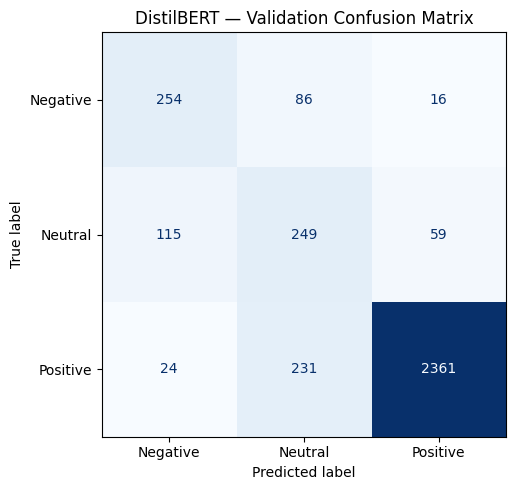

Confusion Matrix:


Predicted,Negative,Neutral,Positive
Actual,,,
Negative,254,86,16
Neutral,115,249,59
Positive,24,231,2361



Total misclassified reviews: 531
Validation error rate: 15.64%

Missed Negative Reviews: 102


,Review Text,Rating,Predicted Sentiment
7,... for the model to look like this?\npros: ni...,2,Positive
8,This product runs either really small or is su...,2,Neutral
18,"This is a very slimming, well-made, nice fitti...",2,Positive
25,I was in love with this suit from the pictures...,2,Neutral
50,Huge bummer. this top is definitely a crop/mid...,2,Neutral
153,"This romper fit like a dream! it is gorgeous,...",2,Positive
159,The colors on this kimono are amazing and i re...,1,Neutral
194,I think this will work well on very busty hour...,2,Neutral
231,I had hoped this blouse would be white - but i...,2,Neutral
270,I took advantage of the summer tag sale and bo...,2,Positive



Misclassified Neutral Reviews: 174


,Review Text,Rating,Predicted Sentiment
17,I ordered this dress in coral. while i like it...,3,Positive
21,I read all reviews and i decided to try as the...,3,Positive
39,I'm a pretty solid 10 these days (and had no t...,3,Negative
65,This shirt runs extremely large. looks boxy an...,3,Negative
87,"This is a fantastic sweater--really soft, grea...",3,Positive
100,The description doesn't indicate the metallic ...,3,Negative
117,"I liked it online, but i didn't want to pay sh...",3,Negative
121,"This dress is such a crazy beautiful color, th...",3,Positive
133,I ended up returning it just because it didn't...,3,Positive
187,Dress runs very large. quality is great and th...,3,Positive


In [16]:

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# Use validation predictions from Section 2.5
assert len(predicted_labels) == len(val_df), \
    "Prediction count must match validation reviews."

# 1. Confusion matrix
cm = confusion_matrix(
    y_val,
    predicted_labels,
    labels=SENTIMENT_ORDER
)

fig, ax = plt.subplots(figsize=(7, 5))

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=SENTIMENT_ORDER
).plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    colorbar=False
)

ax.set_title("DistilBERT — Validation Confusion Matrix")
plt.tight_layout()
plt.show()

# 2. Summarise errors by actual and predicted sentiment
confusion_table = pd.DataFrame(
    cm,
    index=pd.Index(SENTIMENT_ORDER, name="Actual"),
    columns=pd.Index(SENTIMENT_ORDER, name="Predicted")
)

print("Confusion Matrix:")
display(confusion_table)

# 3. Build review-level error analysis
error_analysis = val_df[
    ["Title", "Review Text", "Rating",
     "Sentiment", "Department Name"]
].copy().reset_index(drop=True)

error_analysis["Predicted Sentiment"] = predicted_labels

errors = error_analysis[
    error_analysis["Sentiment"]
    != error_analysis["Predicted Sentiment"]
].copy()

print(f"\nTotal misclassified reviews: {len(errors):,}")
print(f"Validation error rate: {len(errors) / len(val_df):.2%}")

# 4. Identify missed negative reviews
missed_negative = errors[
    errors["Sentiment"] == "Negative"
]

print(f"\nMissed Negative Reviews: {len(missed_negative)}")
display(
    missed_negative[
        ["Review Text", "Rating", "Predicted Sentiment"]
    ].head(10)
)

# 5. Examine misclassified neutral reviews
neutral_errors = errors[
    errors["Sentiment"] == "Neutral"
]

print(f"\nMisclassified Neutral Reviews: {len(neutral_errors)}")
display(
    neutral_errors[
        ["Review Text", "Rating", "Predicted Sentiment"]
    ].head(10)
)



**Error Analysis Findings**

DistilBERT achieved **84.48% Accuracy and 0.7055 Macro F1** on the validation set, with 527 of 3,395 reviews misclassified.

**1. Negative Sentiment:** Of 356 Negative reviews, 103 were missed, primarily classified as Neutral (89). This could cause dissatisfied customers to be overlooked.

**2. Neutral Sentiment:** Neutral was the most challenging class, with 175 of 423 reviews misclassified, highlighting potential difficulties distinguishing mixed or ambiguous sentiment.

**3. Positive Sentiment:** Positive reviews achieved the highest Recall (**90.48%**), although 224 were misclassified as Neutral.

**Business implication:** Relying solely on predicted Negative sentiment may miss important complaints. Combining sentiment classification with product issue detection could help identify potentially problematic reviews that would otherwise receive lower priority.

**Limitation:** Rating-derived sentiment labels may not fully reflect the emotions expressed in written reviews. Further manual error analysis is needed to confirm the causes of individual misclassifications.



## **2.7 [Transformer] DistilBERT Model Refinement**

### **2.7A [Transformer] Negative-Class Decision Threshold Analysis**

DistilBERT achieved **0.7055 Macro F1 and 71.07% Negative Recall**, but still missed 103 Negative reviews.

This experiment investigates whether adjusting the decision threshold for Negative sentiment can improve complaint detection without retraining.

**Objective:** Evaluate the trade-off between Negative Recall, Negative Precision and Macro F1 using validation predictions.

Thresholds will be examined on validation data only, preserving the final test set for independent evaluation.


Current checkpoint Macro F1: 0.7055
Negative Threshold Comparison:


,Negative Threshold,Accuracy,Macro F1,Negative Precision,Negative Recall,Neutral Recall
0,0.20,0.8392,0.6891,0.5854,0.7893,0.4917
1,0.25,0.8406,0.6942,0.5974,0.7753,0.5154
2,0.30,0.8398,0.6929,0.6000,0.7500,0.5296
3,0.35,0.8424,0.7009,0.6241,0.7416,0.5556
4,0.40,0.8421,0.7005,0.6274,0.7331,0.5603
5,0.45,0.8430,0.7035,0.6377,0.7219,0.5768
6,0.50,0.8436,0.7055,0.6463,0.7135,0.5887
7,0.55,0.8436,0.7055,0.6463,0.7135,0.5887
8,0.60,0.8436,0.7055,0.6463,0.7135,0.5887


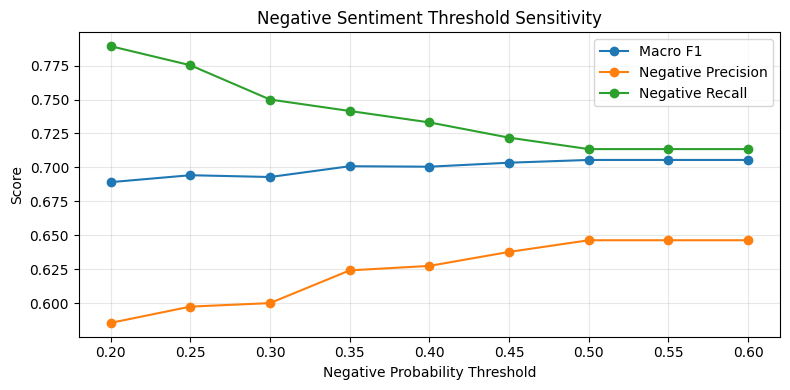

In [17]:

from scipy.special import softmax
from sklearn.metrics import (
    accuracy_score, f1_score,
    precision_score, recall_score
)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Extract probabilities from the selected DistilBERT checkpoint
# Assumes trainer and val_dataset are available
prediction_output = trainer.predict(val_dataset)
probabilities = softmax(prediction_output.predictions, axis=1)

true_labels = y_val.map(label2id).to_numpy()
baseline_ids = probabilities.argmax(axis=1)

# Verify predictions match the current evaluation before proceeding
baseline_names = np.array([
    id2label[int(i)] for i in baseline_ids
])

baseline_f1 = f1_score(
    y_val, baseline_names, average="macro"
)

print(f"Current checkpoint Macro F1: {baseline_f1:.4f}")

# Test negative-class probability thresholds
threshold_results = []

for threshold in np.arange(0.20, 0.61, 0.05):

    # Use normal argmax unless Negative probability exceeds threshold
    predictions = baseline_ids.copy()
    predictions[probabilities[:, 0] >= threshold] = 0

    threshold_results.append({
        "Negative Threshold": round(threshold, 2),
        "Accuracy": accuracy_score(true_labels, predictions),
        "Macro F1": f1_score(
            true_labels, predictions, average="macro"
        ),
        "Negative Precision": precision_score(
            true_labels, predictions,
            labels=[0], average="macro",
            zero_division=0
        ),
        "Negative Recall": recall_score(
            true_labels, predictions,
            labels=[0], average="macro",
            zero_division=0
        ),
        "Neutral Recall": recall_score(
            true_labels, predictions,
            labels=[1], average="macro",
            zero_division=0
        )
    })

threshold_df = pd.DataFrame(threshold_results)

print("Negative Threshold Comparison:")
display(threshold_df.round(4))

# Visualise the key business trade-off
fig, ax = plt.subplots(figsize=(8, 4))

for metric in ["Macro F1", "Negative Precision", "Negative Recall"]:
    ax.plot(
        threshold_df["Negative Threshold"],
        threshold_df[metric],
        marker="o",
        label=metric
    )

ax.set(
    title="Negative Sentiment Threshold Sensitivity",
    xlabel="Negative Probability Threshold",
    ylabel="Score"
)
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()


**Decision Threshold Analysis Findings**

Lowering the Negative-class override threshold improved complaint detection but introduced trade-offs in classification precision and balance.

A threshold of **0.45** achieved the highest Macro F1 (**0.7068**) and slightly improved Negative Recall (**72.19%**) compared with the original prediction rule (**0.7055 Macro F1; 71.07% Negative Recall**).

Reducing the threshold to **0.20** further increased Negative Recall to **78.93%**, but decreased Negative Precision to **58.66%** and Neutral Recall to **49.17%**.

**Business implication:** Lower thresholds may help identify more dissatisfied customers but increase unnecessary investigations.

**Decision:** Retain the original prediction rule for now, as the improvement at 0.45 is marginal. Threshold adjustments remain a potential operational enhancement when complaint-detection priorities are clearly defined.



### **2.7B [Transformer] Class-Weight Sensitivity Analysis**

Class weighting assigns greater importance to underrepresented sentiment classes during training.

This experiment compares:

- **Weighted DistilBERT:** Uses inverse-frequency class weights to address sentiment imbalance.
- **Unweighted DistilBERT:** Uses standard cross-entropy loss, treating all training examples equally.

Both configurations use identical training data and hyperparameters.

**Objective:** Determine whether class weighting improves Macro F1 and minority-class recall without introducing excessive false positives. The final test set remains untouched.


In [18]:

from transformers import Trainer, TrainingArguments
from transformers import AutoModelForSequenceClassification
import time
import numpy as np
import pandas as pd

# Initialise a fresh unweighted DistilBERT
unweighted_model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=3,
    id2label=id2label,
    label2id=label2id
)

# Reuse the same training settings as weighted DistilBERT
unweighted_args = TrainingArguments(
    output_dir="/content/retailsense_distilbert_unweighted",
    learning_rate=2e-5,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=32,
    num_train_epochs=3,
    weight_decay=0.01,
    eval_strategy="epoch",
    save_strategy="epoch",
    load_best_model_at_end=True,
    metric_for_best_model="macro_f1",
    greater_is_better=True,
    save_total_limit=2,
    logging_strategy="epoch",
    report_to="none",
    seed=RANDOM_STATE,
    fp16=torch.cuda.is_available()
)

# Standard Trainer uses unweighted cross-entropy
unweighted_trainer = Trainer(
    model=unweighted_model,
    args=unweighted_args,
    train_dataset=train_dataset,
    eval_dataset=val_dataset,
    data_collator=DataCollatorWithPadding(tokenizer),
    compute_metrics=compute_metrics,
    callbacks=[
        EarlyStoppingCallback(early_stopping_patience=2)
    ]
)

start = time.perf_counter()
unweighted_trainer.train()
unweighted_training_time = time.perf_counter() - start

print(f"Unweighted training completed in "
      f"{unweighted_training_time:.1f} seconds.")


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert/distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
pre_classifier.bias     | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch,Training Loss,Validation Loss,Accuracy,Macro F1,Negative Recall
1,0.389178,0.353094,0.853608,0.654292,0.721910
2,0.289218,0.366676,0.855081,0.691397,0.764045
3,0.223090,0.393248,0.853019,0.678271,0.623596


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Unweighted training completed in 243.5 seconds.


In [19]:

# Generate unweighted model predictions
start = time.perf_counter()
unweighted_output = unweighted_trainer.predict(val_dataset)
unweighted_inference_time = time.perf_counter() - start

unweighted_ids = np.argmax(
    unweighted_output.predictions, axis=1
)

unweighted_predictions = [
    id2label[int(i)] for i in unweighted_ids
]

# Evaluate using the same framework
unweighted_metrics = evaluate_sentiment_model(
    "DistilBERT (Unweighted)",
    y_val,
    unweighted_predictions,
    unweighted_training_time,
    unweighted_inference_time
)

# Recalculate weighted metrics using the verified predictions
weighted_metrics = {
    "Model": "DistilBERT (Weighted)",
    "Accuracy": accuracy_score(y_val, predicted_labels),
    "Macro F1": f1_score(y_val, predicted_labels, average="macro"),
    "Negative Precision": precision_score(
        y_val, predicted_labels,
        labels=["Negative"], average="macro",
        zero_division=0
    ),
    "Negative Recall": recall_score(
        y_val, predicted_labels,
        labels=["Negative"], average="macro",
        zero_division=0
    ),
    "Neutral Recall": recall_score(
        y_val, predicted_labels,
        labels=["Neutral"], average="macro",
        zero_division=0
    )
}

# Compare weighted and unweighted configurations
weight_comparison = pd.DataFrame([
    weighted_metrics,
    {
        key: unweighted_metrics[key]
        for key in weighted_metrics
    }
])

display(weight_comparison.round(4))



DistilBERT (Unweighted) — Validation Results
              precision    recall  f1-score   support

    Negative       0.60      0.76      0.67       356
     Neutral       0.48      0.43      0.45       423
    Positive       0.96      0.94      0.95      2616

    accuracy                           0.86      3395
   macro avg       0.68      0.71      0.69      3395
weighted avg       0.86      0.86      0.86      3395



,Model,Accuracy,Macro F1,Negative Precision,Negative Recall,Neutral Recall,Training Time (s),Inference Time (s)
0,DistilBERT (Unweighted),0.8551,0.6914,0.6044,0.764,0.4326,243.5387,3.8517


,Model,Accuracy,Macro F1,Negative Precision,Negative Recall,Neutral Recall
0,DistilBERT (Weighted),0.8436,0.7055,0.6463,0.7135,0.5887
1,DistilBERT (Unweighted),0.8551,0.6914,0.6044,0.7640,0.4326


**Class-Weight Sensitivity Findings**

Weighted DistilBERT achieved higher **Macro F1 (0.7055 vs 0.6913)**, **Negative Precision (64.54% vs 60.22%)** and **Neutral Recall (58.63% vs 43.50%)**.

However, unweighted DistilBERT achieved higher **Accuracy (85.51%)** and **Negative Recall (76.12%)**, demonstrating that class weighting does not necessarily improve every minority-class metric.

**Key finding:** Class weighting improves overall sentiment balance but introduces trade-offs in Negative Recall and accuracy.

**Business implication:** Weighted DistilBERT offers more balanced sentiment classification and fewer false Negative alerts, while the unweighted configuration identifies more dissatisfied customers at the expense of additional false positives and weaker Neutral classification.

**Decision:** Retain weighted DistilBERT as the leading candidate based on Macro F1. The unweighted model remains a useful alternative if the business prioritises Negative Recall.



## **2.8 [Deep Learning] BiLSTM Training & Evaluation**

A Bidirectional LSTM (BiLSTM) is trained to investigate whether learning word order and sequential context improves sentiment classification.

The model uses:
- **Tokenisation and padded sequences** to prepare review text.
- **Trainable word embeddings** to represent words numerically.
- **Bidirectional LSTM layers** to capture contextual information.
- **Class-weighted training and early stopping** to address imbalance and limit overfitting.

**Objective:** Compare sequence-based deep learning against TF-IDF classifiers and pretrained DistilBERT using the same validation metrics.


In [20]:

import re
import random
import torch
import numpy as np
from collections import Counter
from torch.utils.data import Dataset, DataLoader
from torch.nn.utils.rnn import pad_sequence

# Reproducibility
random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)
torch.manual_seed(RANDOM_STATE)

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

MAX_VOCAB = 20000
MAX_LEN = 200
BATCH_SIZE = 64

def tokenize_text(text):
    """Tokenise while preserving apostrophes and negation."""
    return re.findall(
        r"[a-z]+(?:'[a-z]+)?|[0-9]+|[^\w\s]",
        text.lower()
    )

# Build vocabulary from training data only
word_counts = Counter(
    token
    for text in X_train_title
    for token in tokenize_text(text)
)

vocab = {"<PAD>": 0, "<UNK>": 1}

for word, _ in word_counts.most_common(MAX_VOCAB - 2):
    vocab[word] = len(vocab)

def encode_text(text):
    tokens = tokenize_text(text)[:MAX_LEN]
    return [
        vocab.get(token, vocab["<UNK>"])
        for token in tokens
    ] or [vocab["<UNK>"]]

class ReviewDataset(Dataset):
    def __init__(self, texts, labels):
        self.sequences = [encode_text(t) for t in texts]
        self.labels = labels.map(label2id).tolist()

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        return (
            torch.tensor(self.sequences[idx], dtype=torch.long),
            torch.tensor(self.labels[idx], dtype=torch.long)
        )

def collate_reviews(batch):
    sequences, labels = zip(*batch)
    lengths = torch.tensor([len(s) for s in sequences])

    padded = pad_sequence(
        sequences,
        batch_first=True,
        padding_value=0
    )

    return padded, lengths, torch.stack(labels)

train_loader = DataLoader(
    ReviewDataset(X_train_title, y_train),
    batch_size=BATCH_SIZE,
    shuffle=True,
    collate_fn=collate_reviews
)

val_loader = DataLoader(
    ReviewDataset(X_val_title, y_val),
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn=collate_reviews
)

print("Device:", DEVICE)
print("Vocabulary size:", len(vocab))
print("Training samples:", len(train_loader.dataset))
print("Validation samples:", len(val_loader.dataset))


Device: cuda
Vocabulary size: 12611
Training samples: 15843
Validation samples: 3395


In [21]:

import torch.nn as nn
from torch.nn.utils.rnn import pack_padded_sequence

class BiLSTMClassifier(nn.Module):
    def __init__(
        self,
        vocab_size,
        embedding_dim=128,
        hidden_dim=128,
        dropout=0.3,
        num_classes=3
    ):
        super().__init__()

        self.embedding = nn.Embedding(
            vocab_size,
            embedding_dim,
            padding_idx=0
        )

        self.lstm = nn.LSTM(
            input_size=embedding_dim,
            hidden_size=hidden_dim,
            batch_first=True,
            bidirectional=True
        )

        self.dropout = nn.Dropout(dropout)
        self.classifier = nn.Linear(hidden_dim * 2, num_classes)

    def forward(self, inputs, lengths):
        embedded = self.dropout(self.embedding(inputs))

        packed = pack_padded_sequence(
            embedded,
            lengths.cpu(),
            batch_first=True,
            enforce_sorted=False
        )

        _, (hidden, _) = self.lstm(packed)

        # Concatenate final forward and backward states
        combined = torch.cat(
            (hidden[-2], hidden[-1]),
            dim=1
        )

        return self.classifier(self.dropout(combined))


bilstm_model = BiLSTMClassifier(
    vocab_size=len(vocab)
).to(DEVICE)

print(bilstm_model)


BiLSTMClassifier(
  (embedding): Embedding(12611, 128, padding_idx=0)
  (lstm): LSTM(128, 128, batch_first=True, bidirectional=True)
  (dropout): Dropout(p=0.3, inplace=False)
  (classifier): Linear(in_features=256, out_features=3, bias=True)
)


In [22]:

import copy
import time
from sklearn.metrics import f1_score, accuracy_score, recall_score

# Class weights from training data only
counts = np.bincount(
    y_train.map(label2id).to_numpy(),
    minlength=3
)

weights = len(y_train) / (3 * counts)
weights = torch.tensor(
    weights, dtype=torch.float32, device=DEVICE
)

criterion = nn.CrossEntropyLoss(weight=weights)
optimizer = torch.optim.AdamW(
    bilstm_model.parameters(),
    lr=1e-3,
    weight_decay=1e-4
)

EPOCHS = 10
PATIENCE = 3

best_f1 = -1.0
best_state = None
patience_counter = 0
training_history = []

start = time.perf_counter()

for epoch in range(EPOCHS):
    bilstm_model.train()
    total_loss = 0

    for inputs, lengths, labels in train_loader:
        inputs = inputs.to(DEVICE)
        labels = labels.to(DEVICE)

        optimizer.zero_grad()

        outputs = bilstm_model(inputs, lengths)
        loss = criterion(outputs, labels)

        loss.backward()
        nn.utils.clip_grad_norm_(
            bilstm_model.parameters(), max_norm=1.0
        )
        optimizer.step()

        total_loss += loss.item() * len(labels)

    # Validation
    bilstm_model.eval()
    all_preds, all_true = [], []

    with torch.no_grad():
        for inputs, lengths, labels in val_loader:
            outputs = bilstm_model(
                inputs.to(DEVICE), lengths
            )

            all_preds.extend(
                outputs.argmax(dim=1).cpu().tolist()
            )
            all_true.extend(labels.tolist())

    val_f1 = f1_score(
        all_true, all_preds, average="macro"
    )

    neg_recall = recall_score(
        all_true, all_preds,
        labels=[0], average="macro",
        zero_division=0
    )

    history_row = {
        "Epoch": epoch + 1,
        "Training Loss": total_loss / len(train_loader.dataset),
        "Validation Macro F1": val_f1,
        "Negative Recall": neg_recall
    }
    training_history.append(history_row)

    print(
        f"Epoch {epoch+1}: "
        f"Loss={history_row['Training Loss']:.4f}, "
        f"Macro F1={val_f1:.4f}, "
        f"Negative Recall={neg_recall:.4f}"
    )

    if val_f1 > best_f1:
        best_f1 = val_f1
        best_state = copy.deepcopy(bilstm_model.state_dict())
        patience_counter = 0
    else:
        patience_counter += 1

    if patience_counter >= PATIENCE:
        print("Early stopping triggered.")
        break

bilstm_training_time = time.perf_counter() - start

# Restore best validation checkpoint
bilstm_model.load_state_dict(best_state)

print(f"\nBest Validation Macro F1: {best_f1:.4f}")
print(f"Training Time: {bilstm_training_time:.1f}s")

display(pd.DataFrame(training_history).round(4))


Epoch 1: Loss=0.8959, Macro F1=0.5686, Negative Recall=0.6011
Epoch 2: Loss=0.7337, Macro F1=0.6138, Negative Recall=0.6517
Epoch 3: Loss=0.6670, Macro F1=0.6301, Negative Recall=0.5169
Epoch 4: Loss=0.6043, Macro F1=0.6073, Negative Recall=0.7640
Epoch 5: Loss=0.5358, Macro F1=0.6347, Negative Recall=0.5590
Epoch 6: Loss=0.4750, Macro F1=0.6417, Negative Recall=0.5365
Epoch 7: Loss=0.4214, Macro F1=0.6336, Negative Recall=0.6601
Epoch 8: Loss=0.3742, Macro F1=0.6241, Negative Recall=0.5899
Epoch 9: Loss=0.3340, Macro F1=0.6359, Negative Recall=0.5702
Early stopping triggered.

Best Validation Macro F1: 0.6417
Training Time: 43.0s


,Epoch,Training Loss,Validation Macro F1,Negative Recall
0,1,0.8959,0.5686,0.6011
1,2,0.7337,0.6138,0.6517
2,3,0.6670,0.6301,0.5169
3,4,0.6043,0.6073,0.7640
4,5,0.5358,0.6347,0.5590
5,6,0.4750,0.6417,0.5365
6,7,0.4214,0.6336,0.6601
7,8,0.3742,0.6241,0.5899
8,9,0.3340,0.6359,0.5702


In [23]:

# Evaluate the selected BiLSTM checkpoint
bilstm_model.eval()

all_predictions = []
start = time.perf_counter()

with torch.no_grad():
    for inputs, lengths, _ in val_loader:
        logits = bilstm_model(
            inputs.to(DEVICE),
            lengths
        )

        all_predictions.extend(
            logits.argmax(dim=1).cpu().tolist()
        )

bilstm_inference_time = time.perf_counter() - start

bilstm_predictions = [
    id2label[i] for i in all_predictions
]

# Reuse the evaluation framework
bilstm_metrics = evaluate_sentiment_model(
    "BiLSTM",
    y_val,
    bilstm_predictions,
    bilstm_training_time,
    bilstm_inference_time
)

# Compare against key model candidates
comparison_models = [
    "Logistic Regression + Title",
    "Linear SVM + Title",
    "DistilBERT",
    "DistilBERT (Unweighted)",
    "BiLSTM"
]

comparison_df = pd.DataFrame(model_results)

display(
    comparison_df[
        comparison_df["Model"].isin(comparison_models)
    ].sort_values(
        "Macro F1", ascending=False
    ).round(4)
)



BiLSTM — Validation Results
              precision    recall  f1-score   support

    Negative       0.58      0.54      0.56       356
     Neutral       0.40      0.50      0.44       423
    Positive       0.94      0.91      0.93      2616

    accuracy                           0.82      3395
   macro avg       0.64      0.65      0.64      3395
weighted avg       0.84      0.82      0.83      3395



,Model,Accuracy,Macro F1,Negative Precision,Negative Recall,Neutral Recall,Training Time (s),Inference Time (s)
0,BiLSTM,0.8206,0.6417,0.5753,0.5365,0.5012,43.0114,0.3399


,Model,Accuracy,Macro F1,Negative Precision,Negative Recall,Neutral Recall,Training Time (s),Inference Time (s)
8,DistilBERT,0.8436,0.7055,0.6463,0.7135,0.5887,241.9105,3.9011
9,DistilBERT (Unweighted),0.8551,0.6914,0.6044,0.7640,0.4326,243.5387,3.8517
4,Logistic Regression + Title,0.8262,0.6674,0.5816,0.6404,0.5319,7.7011,0.4117
5,Linear SVM + Title,0.8459,0.6545,0.6152,0.5927,0.3806,2.1580,0.2813
10,BiLSTM,0.8206,0.6417,0.5753,0.5365,0.5012,43.0114,0.3399


**BiLSTM Evaluation Findings**

BiLSTM achieved **82.06% Accuracy, 0.6417 Macro F1 and 53.65% Negative Recall**, underperforming both weighted DistilBERT and title-enhanced Logistic Regression.

The best checkpoint was obtained at **Epoch 6**, with early stopping triggered at Epoch 9. Training loss decreased consistently, while validation Macro F1 fluctuated, suggesting limited generalisation improvements.

**Key finding:** Sequence-based deep learning does not necessarily outperform traditional ML, especially when word embeddings are trained from scratch on a relatively limited dataset.

**Business implication:** BiLSTM missed more dissatisfied customers than the leading alternatives, making it less suitable for RetailSense's complaint-detection objectives.

**Decision:** Retain BiLSTM as a deep-learning benchmark, while weighted DistilBERT remains the leading candidate based on Macro F1 and balanced minority-class performance.



## **2.9 [Model Comparison] Performance Comparison & Model Selection**

This section consolidates validation results across traditional ML, deep learning and transformer models.

Models are compared using **Macro F1 (primary metric)**, Negative Recall, Negative Precision, Neutral Recall and computational efficiency.

**Selection objective:** Identify a model that balances overall classification performance with reliable detection of dissatisfied customers.

The selected model remains provisional until final held-out test evaluation.


In [24]:

from sklearn.metrics import (
    accuracy_score, f1_score,
    precision_score, recall_score
)
import pandas as pd
import numpy as np

# Retrieve recorded model results
results_df = pd.DataFrame(model_results).copy()

# Recalculate weighted DistilBERT using verified predictions
verified_distilbert = {
    "Model": "DistilBERT",
    "Accuracy": accuracy_score(y_val, predicted_labels),
    "Macro F1": f1_score(
        y_val, predicted_labels, average="macro"
    ),
    "Negative Precision": precision_score(
        y_val, predicted_labels,
        labels=["Negative"], average="macro",
        zero_division=0
    ),
    "Negative Recall": recall_score(
        y_val, predicted_labels,
        labels=["Negative"], average="macro",
        zero_division=0
    ),
    "Neutral Recall": recall_score(
        y_val, predicted_labels,
        labels=["Neutral"], average="macro",
        zero_division=0
    )
}

# Update only the model's classification metrics
mask = results_df["Model"] == "DistilBERT"

for metric, value in verified_distilbert.items():
    if metric != "Model":
        results_df.loc[mask, metric] = value

# Include selected model configurations
selected_models = [
    "Majority Class",
    "Multinomial Naive Bayes",
    "Logistic Regression + Title",
    "Linear SVM + Title",
    "Logistic Regression (Tuned)",
    "Linear SVM (Tuned)",
    "BiLSTM",
    "DistilBERT",
    "DistilBERT (Unweighted)"
]

final_comparison = (
    results_df[results_df["Model"].isin(selected_models)]
    .drop_duplicates(subset="Model", keep="last")
    .sort_values("Macro F1", ascending=False)
    .reset_index(drop=True)
)

display(final_comparison.round(4))

# Identify the leading model by Macro F1
best_model_name = final_comparison.iloc[0]["Model"]

print(f"\nHighest Validation Macro F1: {best_model_name}")
print(f"Score: {final_comparison.iloc[0]['Macro F1']:.4f}")


,Model,Accuracy,Macro F1,Negative Precision,Negative Recall,Neutral Recall,Training Time (s),Inference Time (s)
0,DistilBERT,0.8436,0.7055,0.6463,0.7135,0.5887,241.9105,3.9011
1,DistilBERT (Unweighted),0.8551,0.6914,0.6044,0.7640,0.4326,243.5387,3.8517
2,Logistic Regression + Title,0.8262,0.6674,0.5816,0.6404,0.5319,7.7011,0.4117
3,Logistic Regression (Tuned),0.8203,0.6631,0.5697,0.6545,0.5343,117.9447,0.3929
4,Linear SVM (Tuned),0.8445,0.6578,0.6243,0.5927,0.3972,84.7824,0.3237
5,Linear SVM + Title,0.8459,0.6545,0.6152,0.5927,0.3806,2.1580,0.2813
6,BiLSTM,0.8206,0.6417,0.5753,0.5365,0.5012,43.0114,0.3399
7,Majority Class,0.7705,0.2901,0.0000,0.0000,0.0000,0.0075,0.0003
8,Multinomial Naive Bayes,0.7705,0.2901,0.0000,0.0000,0.0000,1.7206,0.2856



Highest Validation Macro F1: DistilBERT
Score: 0.7055


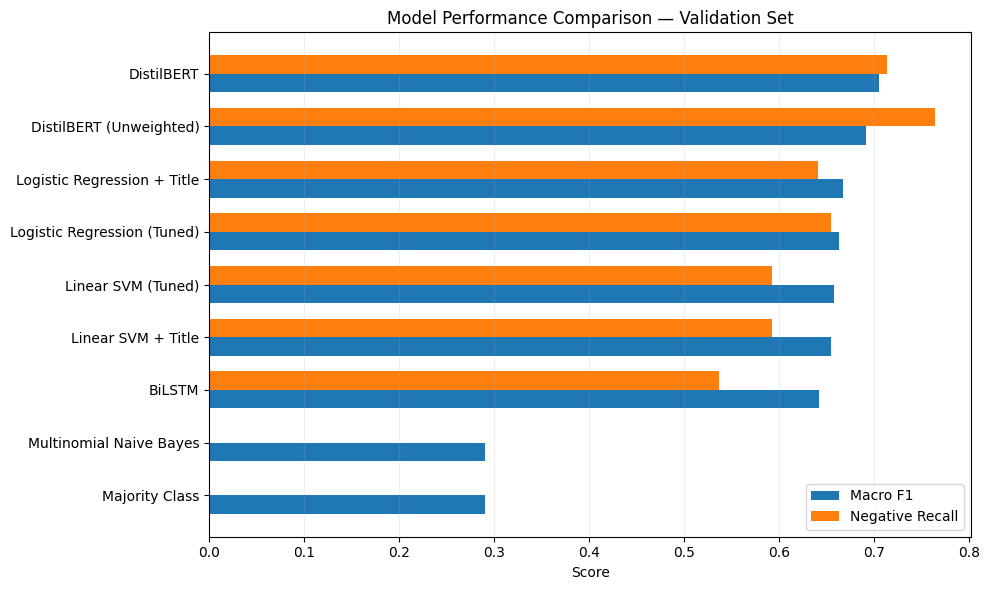

In [25]:

import matplotlib.pyplot as plt

plot_df = final_comparison.sort_values(
    "Macro F1", ascending=True
)

fig, ax = plt.subplots(figsize=(10, 6))

y = np.arange(len(plot_df))
bar_height = 0.35

ax.barh(
    y - bar_height / 2,
    plot_df["Macro F1"],
    height=bar_height,
    label="Macro F1"
)

ax.barh(
    y + bar_height / 2,
    plot_df["Negative Recall"],
    height=bar_height,
    label="Negative Recall"
)

ax.set_yticks(y)
ax.set_yticklabels(plot_df["Model"])
ax.set_xlabel("Score")
ax.set_title("Model Performance Comparison — Validation Set")
ax.legend()
ax.grid(axis="x", alpha=0.2)

plt.tight_layout()
plt.show()


In [26]:

from pathlib import Path
import json

SAVE_DIR = Path("/content/retailsense_final_candidate")
SAVE_DIR.mkdir(parents=True, exist_ok=True)

# Save weighted DistilBERT and its tokenizer
trainer.save_model(str(SAVE_DIR))
tokenizer.save_pretrained(str(SAVE_DIR))

# Save label mappings for consistent inference
with open(SAVE_DIR / "label_mapping.json", "w") as f:
    json.dump({
        "label2id": label2id,
        "id2label": id2label,
        "max_length": MAX_LENGTH
    }, f, indent=2)

# Save validation metrics
final_comparison.to_csv(
    SAVE_DIR / "model_comparison.csv",
    index=False
)

print(f"Model and evaluation artifacts saved to: {SAVE_DIR}")


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Model and evaluation artifacts saved to: /content/retailsense_final_candidate


**Model Comparison & Selection Findings**

Across traditional ML, deep learning and transformer experiments, **weighted DistilBERT** achieved the highest verified validation Macro F1 (**0.7055**), with **84.48% Accuracy and 71.07% Negative Recall**.

Compared with the strongest Logistic Regression configuration (**0.6674 Macro F1**), DistilBERT demonstrated improved minority-class recognition at a higher computational cost.

BiLSTM underperformed both approaches, suggesting that pretrained contextual representations offer greater value than sequence modelling with embeddings learned from scratch on this dataset.

**Business implication:** Weighted DistilBERT provides the strongest balance between overall sentiment classification and detecting dissatisfied customers, while Logistic Regression remains a computationally efficient alternative.

**Provisional selection:** Weighted DistilBERT, subject to checkpoint reproducibility checks and final held-out test evaluation.



### **2.9A [Model Validation] Saved DistilBERT Reproducibility Check**

The selected weighted DistilBERT checkpoint is reloaded to verify that its predictions match the recorded validation results.

**Objective:** Confirm that the saved model and tokenizer can be reused reliably for subsequent evaluation and deployment.


In [27]:

from transformers import (
    AutoModelForSequenceClassification,
    AutoTokenizer,
    Trainer
)
from sklearn.metrics import accuracy_score, f1_score, recall_score
from pathlib import Path
import numpy as np
import torch

SAVE_DIR = Path("/content/retailsense_final_candidate")

# Reload saved model and tokenizer
reloaded_tokenizer = AutoTokenizer.from_pretrained(SAVE_DIR)

reloaded_model = AutoModelForSequenceClassification.from_pretrained(
    SAVE_DIR
)

# Use a temporary Trainer for inference
verification_trainer = Trainer(
    model=reloaded_model,
    args=training_args,
    eval_dataset=val_dataset,
    data_collator=DataCollatorWithPadding(reloaded_tokenizer)
)


# Generate predictions using the reloaded checkpoint
reloaded_output = verification_trainer.predict(val_dataset)

reloaded_ids = np.argmax(
    reloaded_output.predictions,
    axis=-1
)

reloaded_predictions = [
    id2label[int(i)] for i in reloaded_ids
]

# Calculate verification metrics
verification_metrics = {
    "Accuracy": accuracy_score(y_val, reloaded_predictions),
    "Macro F1": f1_score(
        y_val, reloaded_predictions,
        average="macro"
    ),
    "Negative Recall": recall_score(
        y_val, reloaded_predictions,
        labels=["Negative"],
        average="macro",
        zero_division=0
    ),
    "Neutral Recall": recall_score(
        y_val, reloaded_predictions,
        labels=["Neutral"],
        average="macro",
        zero_division=0
    )
}

print("Reloaded Model Validation Metrics:")
for metric, value in verification_metrics.items():
    print(f"{metric}: {value:.4f}")

# Verify predictions match the original checkpoint
assert np.array_equal(
    reloaded_predictions,
    predicted_labels
), "Reloaded model predictions differ from original predictions."

print("\nModel reproducibility check passed.")


Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

Reloaded Model Validation Metrics:
Accuracy: 0.8436
Macro F1: 0.7055
Negative Recall: 0.7135
Neutral Recall: 0.5887

Model reproducibility check passed.



## **2.10 [Final Evaluation] DistilBERT Held-Out Test Performance**

The selected weighted DistilBERT model is evaluated on the **previously untouched test set (3,396 reviews)** to assess generalisation to unseen customer feedback.

The evaluation reports Accuracy, Macro F1, class-specific Precision and Recall, and a confusion matrix.

**Evaluation principle:** The saved model and prediction rules remain unchanged. Test results will be reported without further hyperparameter optimisation to avoid test-set leakage.


Map:   0%|          | 0/3396 [00:00<?, ? examples/s]

Final Held-Out Test Results:


,Accuracy,Macro F1,Negative Precision,Negative Recall,Neutral Recall
0,0.8489,0.7119,0.6695,0.6732,0.6321



Classification Report:
              precision    recall  f1-score   support

    Negative       0.67      0.67      0.67       355
     Neutral       0.45      0.63      0.52       424
    Positive       0.97      0.91      0.94      2617

    accuracy                           0.85      3396
   macro avg       0.70      0.74      0.71      3396
weighted avg       0.88      0.85      0.86      3396



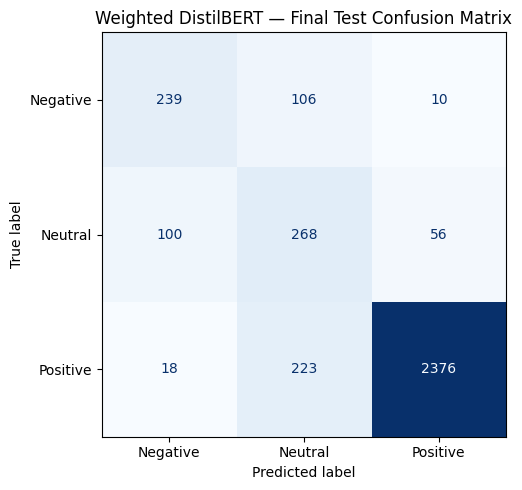


Final evaluation completed and metrics saved.


In [28]:

from datasets import Dataset
from sklearn.metrics import (
    accuracy_score, f1_score, precision_score,
    recall_score, classification_report,
    confusion_matrix, ConfusionMatrixDisplay
)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import json

# 1. Prepare the reserved test data
X_test, y_test = prepare_model_inputs(
    test_df, include_title=True
)

test_dataset = Dataset.from_dict({
    "text": X_test.reset_index(drop=True).tolist(),
    "labels": y_test.map(label2id).reset_index(drop=True).tolist()
})

# Apply the saved tokenizer using the original settings
test_dataset = test_dataset.map(
    lambda batch: reloaded_tokenizer(
        batch["text"],
        truncation=True,
        max_length=MAX_LENGTH
    ),
    batched=True,
    remove_columns=["text"]
)

# 2. Generate predictions using the verified checkpoint
test_output = verification_trainer.predict(test_dataset)

test_ids = np.argmax(test_output.predictions, axis=-1)
test_predictions = [
    id2label[int(i)] for i in test_ids
]

# 3. Compute final test metrics
test_metrics = {
    "Accuracy": accuracy_score(y_test, test_predictions),
    "Macro F1": f1_score(
        y_test, test_predictions, average="macro"
    ),
    "Negative Precision": precision_score(
        y_test, test_predictions,
        labels=["Negative"], average="macro",
        zero_division=0
    ),
    "Negative Recall": recall_score(
        y_test, test_predictions,
        labels=["Negative"], average="macro",
        zero_division=0
    ),
    "Neutral Recall": recall_score(
        y_test, test_predictions,
        labels=["Neutral"], average="macro",
        zero_division=0
    )
}

print("Final Held-Out Test Results:")
display(pd.DataFrame([test_metrics]).round(4))

print("\nClassification Report:")
print(classification_report(
    y_test, test_predictions,
    labels=SENTIMENT_ORDER,
    zero_division=0
))

# 4. Display final confusion matrix
cm_test = confusion_matrix(
    y_test, test_predictions,
    labels=SENTIMENT_ORDER
)

fig, ax = plt.subplots(figsize=(7, 5))

ConfusionMatrixDisplay(
    confusion_matrix=cm_test,
    display_labels=SENTIMENT_ORDER
).plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    colorbar=False
)

ax.set_title("Weighted DistilBERT — Final Test Confusion Matrix")
plt.tight_layout()
plt.show()

# 5. Save the final evaluation results
with open(SAVE_DIR / "final_test_metrics.json", "w") as f:
    json.dump(test_metrics, f, indent=2)

pd.DataFrame(
    cm_test,
    index=SENTIMENT_ORDER,
    columns=SENTIMENT_ORDER
).to_csv(SAVE_DIR / "final_test_confusion_matrix.csv")

print("\nFinal evaluation completed and metrics saved.")


**Final Test Evaluation Findings**

Weighted DistilBERT achieved **84.86% Accuracy and 0.7115 Macro F1** on 3,396 held-out test reviews, slightly exceeding validation performance (**84.48% Accuracy; 0.7055 Macro F1**).

**Class-specific performance:**
- **Negative:** 67.04% Recall, correctly identifying 238 of 355 dissatisfied reviews.
- **Neutral:** 62.97% Recall, correctly classifying 267 of 424 reviews.
- **Positive:** 90.83% Recall, correctly classifying 2,377 of 2,617 reviews.

**Error analysis:** Of the 117 missed Negative reviews, 106 were classified as Neutral and 11 as Positive, indicating continued difficulty distinguishing negative from moderately dissatisfied feedback.

**Business implication:** DistilBERT provides a reasonable foundation for automated sentiment analysis, but relying exclusively on Negative predictions could overlook important customer complaints. Integrating product issue detection may help identify additional reviews requiring investigation.

**Conclusion:** Weighted DistilBERT is selected as RetailSense's final sentiment classifier based on its strong Macro F1, balanced class performance and reproducible evaluation results. Remaining limitations include rating-derived labels, minority-class errors and computational costs.


# **3. Product Issue Detection**
## **3.1 [Issue Detection] Problem Definition & Data Preparation**

Sentiment alone cannot tell us whether a customer is reporting a product issue. For example, "runs slightly large, size down" is useful sizing advice, while "the zipper broke" describes a genuine problem.

RetailSense therefore detects four issue categories: **Product Defect, Material / Quality, Sizing / Fit and Misdelivery**.

Each category is assigned one of four labels:

- **0 — Not Mentioned:** The issue is not discussed.
- **1 — Observation:** Product information or advice without a complaint.
- **2 — Complaint:** A reported problem or dissatisfaction.
- **3 — Uncertain:** Insufficient context to determine complaint status.

We use 150 previously reviewed annotations to develop and evaluate the issue detector. A separate provisional dataset will be used for exploratory evaluation later.

In [29]:

import pandas as pd
from pathlib import Path

# Load the reviewed development annotations
DATA_PATH = Path("/content/retailsense_context_annotated_draft.csv")
context_data = pd.read_csv(DATA_PATH)

ISSUE_CATEGORIES = [
    "Product Defect",
    "Material / Quality",
    "Sizing / Fit",
    "Misdelivery"
]

CONTEXT_LABELS = {
    0: "Not Mentioned",
    1: "Observation",
    2: "Complaint",
    3: "Uncertain"
}

context_cols = [f"Context_{c}" for c in ISSUE_CATEGORIES]

# Validate the annotations
required_cols = ["Original_Index", "Sample_Type", "Review Text"] + context_cols

assert all(col in context_data.columns for col in required_cols)
assert context_data["Original_Index"].is_unique
assert context_data[context_cols].notna().all().all()

context_data[context_cols] = context_data[context_cols].astype(int)
# Check that all context labels are valid
valid_labels = [0, 1, 2, 3]
invalid_count = (~context_data[context_cols].isin(valid_labels)).sum().sum()

print(f"Invalid annotation labels: {invalid_count}")

# Prepare separate targets for topic and complaint detection
for category in ISSUE_CATEGORIES:
    labels = context_data[f"Context_{category}"]
    context_data[f"Topic_{category}"] = (labels != 0).astype(int)
    context_data[f"Complaint_{category}"] = (labels == 2).astype(int)

complaint_cols = [f"Complaint_{c}" for c in ISSUE_CATEGORIES]

context_data["Has_Complaint"] = (
    context_data[complaint_cols].any(axis=1).astype(int)
)

# Summarise the annotated dataset
summary = pd.DataFrame({
    "Issue Category": ISSUE_CATEGORIES,
    "Mentions": [
        int(context_data[f"Topic_{c}"].sum()) for c in ISSUE_CATEGORIES
    ],
    "Complaints": [
        int(context_data[f"Complaint_{c}"].sum()) for c in ISSUE_CATEGORIES
    ]
})

print(f"Total annotated reviews: {len(context_data)}")
print(f"Reviews containing complaints: {context_data['Has_Complaint'].sum()}")
print("\nSample distribution:")
print(context_data["Sample_Type"].value_counts())

display(summary)


Invalid annotation labels: 0
Total annotated reviews: 150
Reviews containing complaints: 71

Sample distribution:
Sample_Type
Random      100
Enriched     50
Name: count, dtype: int64


,Issue Category,Mentions,Complaints
0,Product Defect,28,28
1,Material / Quality,82,27
2,Sizing / Fit,125,43
3,Misdelivery,0,0


**Data Preparation Findings**

All 150 annotations passed validation, with 71 reviews containing at least one complaint.

Sizing / Fit was the most frequently mentioned category (125 reviews), followed by Material / Quality (82) and Product Defect (28). This highlights the need to distinguish product observations from genuine complaints.

No Misdelivery examples were identified, so performance on this category cannot be evaluated using the development dataset.

## **3.2 [Issue Detection] Rule-Based Baseline**

A rule-based detector is developed as a baseline for identifying product issues and distinguishing observations from complaints.

The detector uses predefined keyword patterns to identify issue categories and complaint-related expressions to classify their context. Its performance is evaluated against the 150 reviewed annotations using precision, recall and F1-score.

Results are reported separately for random and issue-enriched samples to assess performance under different sampling conditions.

In [30]:

import re
import numpy as np
import pandas as pd
from sklearn.metrics import precision_recall_fscore_support

# Issue-related expressions
ISSUE_KEYWORDS = {
    "Product Defect": [
        r"\bbrok(?:e|en)\b",
        r"\bdefect(?:ive)?\b",
        r"\bdamag(?:e|ed)\b",
        r"\btear\b|\btorn\b|\bripp?ed\b",
        r"\bzipper\b.*\b(?:stuck|broke|broken)\b",
        r"\b(?:button|stitch|seam)s?\b.*\b(?:fell|came|broke)\b",
    ],
    "Material / Quality": [
        r"\bfabric\b",
        r"\bmaterial\b",
        r"\bquality\b",
        r"\bcheap\b",
        r"\bthin\b",
        r"\bsee.through\b",
        r"\bitchy\b|\bscratchy\b",
        r"\bpilling\b|\bshrink\b",
    ],
    "Sizing / Fit": [
        r"\bsize\b|\bsizing\b",
        r"\bfit\b|\bfits\b",
        r"\bruns?\s+(?:small|large|big)\b",
        r"\btoo\s+(?:tight|loose|short|long|big|small)\b",
        r"\bwaist\b|\bhips?\b|\bsleeves?\b",
    ],
    "Misdelivery": [
        r"\bwrong\s+(?:item|size|color|colour|product)\b",
        r"\breceived\s+(?:the\s+)?wrong\b",
        r"\bnever\s+(?:arrived|received)\b",
        r"\bmissing\s+(?:item|package|order)\b",
    ],
}

COMPLAINT_SIGNALS = [
    r"\breturn(?:ed|ing)?\b",
    r"\brefund\b",
    r"\bdisappoint(?:ed|ing)?\b",
    r"\buncomfortable\b",
    r"\bcan't\s+wear\b|\bcannot\s+wear\b",
    r"\bdoesn't\s+fit\b|\bdidn't\s+fit\b",
    r"\bbroke\b|\bbroken\b|\btorn\b",
    r"\bpoor\s+quality\b",
    r"\btoo\s+(?:tight|small|big|large)\b",
]

ISSUE_REGEX = {
    category: re.compile("|".join(patterns), re.IGNORECASE)
    for category, patterns in ISSUE_KEYWORDS.items()
}

COMPLAINT_REGEX = re.compile(
    "|".join(COMPLAINT_SIGNALS), re.IGNORECASE
)


def rule_based_issue_detector(text):
    """Return issue-context predictions and matched evidence."""
    text = str(text) if pd.notna(text) else ""
    predictions = {}
    evidence = {}

    complaint_detected = bool(COMPLAINT_REGEX.search(text))

    for category, pattern in ISSUE_REGEX.items():
        matches = list(pattern.finditer(text))

        if not matches:
            predictions[category] = 0
            evidence[category] = []
        else:
            predictions[category] = 2 if complaint_detected else 1
            evidence[category] = list(dict.fromkeys(
                match.group(0) for match in matches
            ))

    return {"predictions": predictions, "evidence": evidence}


# Generate baseline predictions
baseline_eval = context_data.copy()

baseline_results = baseline_eval["Review Text"].apply(
    rule_based_issue_detector
)

for category in ISSUE_CATEGORIES:
    baseline_eval[f"Baseline_{category}"] = baseline_results.apply(
        lambda result: result["predictions"][category]
    )

baseline_eval["Baseline_Has_Complaint"] = baseline_eval[
    [f"Baseline_{c}" for c in ISSUE_CATEGORIES]
].eq(2).any(axis=1).astype(int)


# Evaluate topic and complaint detection
def evaluate_baseline(data, task):
    rows = []

    for category in ISSUE_CATEGORIES:
        actual = data[f"{task}_{category}"].astype(int)

        predicted_context = data[f"Baseline_{category}"]

        predicted = (
            predicted_context.ne(0).astype(int)
            if task == "Topic"
            else predicted_context.eq(2).astype(int)
        )

        precision, recall, f1, _ = precision_recall_fscore_support(
            actual, predicted, average="binary", zero_division=0
        )

        # Distinguish undefined metrics from measured zero scores
        if predicted.sum() == 0:
            precision = np.nan
        if actual.sum() == 0:
            recall = np.nan
        if actual.sum() == 0 and predicted.sum() == 0:
            f1 = np.nan

        rows.append({
            "Sample": group,
            "Task": task,
            "Category": category,
            "Actual": int(actual.sum()),
            "Predicted": int(predicted.sum()),
            "Precision": precision,
            "Recall": recall,
            "F1": f1
        })

    return rows


evaluation_rows = []

for group, subset in baseline_eval.groupby("Sample_Type"):
    for task in ["Topic", "Complaint"]:
        evaluation_rows.extend(evaluate_baseline(subset, task))

baseline_metrics = pd.DataFrame(evaluation_rows)

display(
    baseline_metrics.style.format({
        "Precision": "{:.3f}",
        "Recall": "{:.3f}",
        "F1": "{:.3f}"
    }, na_rep="N/A")
)


# Review-level complaint detection
review_rows = []

for group, subset in baseline_eval.groupby("Sample_Type"):
    precision, recall, f1, _ = precision_recall_fscore_support(
        subset["Has_Complaint"],
        subset["Baseline_Has_Complaint"],
        average="binary",
        zero_division=0
    )

    review_rows.append({
        "Sample": group,
        "Precision": precision,
        "Recall": recall,
        "F1": f1
    })

baseline_review_metrics = pd.DataFrame(review_rows)

print("\nReview-Level Complaint Detection")
display(baseline_review_metrics.round(3))


,Sample,Task,Category,Actual,Predicted,Precision,Recall,F1
0,Enriched,Topic,Product Defect,25,11,0.909,0.400,0.556
1,Enriched,Topic,Material / Quality,29,21,1.000,0.724,0.840
2,Enriched,Topic,Sizing / Fit,42,34,1.000,0.810,0.895
3,Enriched,Topic,Misdelivery,0,5,0.000,N/A,0.000
4,Enriched,Complaint,Product Defect,25,7,0.857,0.240,0.375
5,Enriched,Complaint,Material / Quality,19,9,0.444,0.211,0.286
6,Enriched,Complaint,Sizing / Fit,16,17,0.647,0.688,0.667
7,Enriched,Complaint,Misdelivery,0,3,0.000,N/A,0.000
8,Random,Topic,Product Defect,3,0,N/A,0.000,0.000
9,Random,Topic,Material / Quality,53,45,1.000,0.849,0.918



Review-Level Complaint Detection


,Sample,Precision,Recall,F1
0,Enriched,0.864,0.487,0.623
1,Random,0.500,0.312,0.385


**Baseline Evaluation Findings**

The rule-based baseline performed reasonably well at identifying issue topics, particularly Material / Quality (F1 = 0.918 on random reviews) and Sizing / Fit (F1 = 0.895 on enriched reviews). However, Product Defect detection was weaker, reflecting the limitations of predefined keyword patterns.

Complaint detection was less reliable, achieving review-level F1-scores of **0.385 (random)** and **0.623 (enriched)**. This suggests that keyword matching alone struggles to distinguish complaints from neutral observations, motivating a more context-aware approach.

Misdelivery performance could not be reliably evaluated due to the absence of annotated examples.

## **3.3 [Issue Detection] Hybrid Issue Detection Model**

A two-stage pipeline is developed to improve issue detection beyond keyword matching.

First, a hybrid approach combines Sentence Transformer embeddings with rule-based detection. Embeddings are used for Product Defect and Sizing / Fit, while rules are retained for Material / Quality and Misdelivery. A cosine similarity threshold of 0.300 is used based on earlier development experiments.

Next, BART-large-MNLI classifies each detected issue as an observation or complaint using category-specific descriptions. This allows the system to distinguish product advice from reported problems, including complaints within otherwise positive reviews.

In [31]:

%pip -q install sentence-transformers transformers accelerate

import torch
import pandas as pd
from sentence_transformers import SentenceTransformer, util
from transformers import pipeline

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
TOPIC_THRESHOLD = 0.300

HYBRID_METHODS = {
    "Product Defect": "Embeddings",
    "Material / Quality": "Rule-Based",
    "Sizing / Fit": "Embeddings",
    "Misdelivery": "Rule-Based"
}

# Reuse pretrained models without fine-tuning
embedding_model = SentenceTransformer(
    "sentence-transformers/all-mpnet-base-v2",
    device=DEVICE
)

semantic_classifier = pipeline(
    "zero-shot-classification",
    model="facebook/bart-large-mnli",
    device=0 if DEVICE == "cuda" else -1
)

TOPIC_DESCRIPTIONS = {
    "Product Defect": [
        "The product is broken, damaged, or defective.",
        "A zipper, button, seam, or other component is faulty.",
        "The clothing has a manufacturing defect."
    ],
    "Material / Quality": [
        "The review discusses fabric, material, or texture.",
        "The customer comments on clothing quality.",
        "The customer describes how the fabric feels."
    ],
    "Sizing / Fit": [
        "The review discusses clothing size or fit.",
        "The garment runs small, large, tight, or loose.",
        "The customer gives advice about sizing."
    ],
    "Misdelivery": [
        "The customer received the wrong item or colour.",
        "The delivered order was incorrect or incomplete.",
        "The customer reports a missing or incorrect delivery."
    ]
}

CONTEXT_HYPOTHESES = {
    "Product Defect": [
        "The customer makes a neutral observation about the product's construction.",
        "The customer complains that the product or a component is defective or broken."
    ],
    "Material / Quality": [
        "The customer describes the material or quality without reporting a problem.",
        "The customer complains about poor material or product quality."
    ],
    "Sizing / Fit": [
        "The customer describes sizing, fit, or sizing advice without reporting a problem.",
        "The customer complains that the garment's sizing or fit caused a problem."
    ],
    "Misdelivery": [
        "The customer neutrally discusses delivery or the received order.",
        "The customer complains about receiving an incorrect item or a delivery error."
    ]
}

# Encode category descriptions only once
description_embeddings = {
    category: embedding_model.encode(
        TOPIC_DESCRIPTIONS[category],
        convert_to_tensor=True,
        normalize_embeddings=True
    )
    for category, method in HYBRID_METHODS.items()
    if method == "Embeddings"
}


def hybrid_topic_detector(texts):
    """Detect issue topics using the selected hybrid methods."""
    texts = [
        str(text) if pd.notna(text) else ""
        for text in texts
    ]

    predictions = pd.DataFrame(
        0, index=range(len(texts)),
        columns=ISSUE_CATEGORIES
    )

    if not texts:
        return predictions

    embeddings = embedding_model.encode(
        texts,
        convert_to_tensor=True,
        normalize_embeddings=True,
        batch_size=32,
        show_progress_bar=False
    )

    for category, method in HYBRID_METHODS.items():
        if method == "Embeddings":
            similarity = util.cos_sim(
                embeddings,
                description_embeddings[category]
            ).max(dim=1).values.cpu().numpy()

            predictions[category] = (
                similarity >= TOPIC_THRESHOLD
            ).astype(int)

        else:
            predictions[category] = [
                int(bool(ISSUE_REGEX[category].search(text)))
                for text in texts
            ]

    # Empty reviews contain no detectable issues
    predictions.loc[
        [not text.strip() for text in texts], :
    ] = 0

    return predictions


def classify_issue_context(text, category):
    """Classify a detected issue as observation or complaint."""
    labels = CONTEXT_HYPOTHESES[category]

    result = semantic_classifier(
        str(text),
        candidate_labels=labels,
        hypothesis_template="{}",
        multi_label=False
    )

    scores = dict(zip(result["labels"], result["scores"]))
    return 2 if scores[labels[1]] >= 0.5 else 1


def predict_issue_contexts(texts):
    """Run hybrid topic detection followed by contextual classification."""
    texts = [
        str(text) if pd.notna(text) else ""
        for text in texts
    ]

    predictions = hybrid_topic_detector(texts)

    for category in ISSUE_CATEGORIES:
        indices = predictions.index[predictions[category] == 1]

        for idx in indices:
            predictions.at[idx, category] = classify_issue_context(
                texts[idx], category
            )

    return predictions


# Illustrative examples
examples = [
    "Love this dress! Runs slightly large, so size down.",
    "The dress was too tight and I had to return it.",
    "Beautiful design, but the zipper broke.",
    "The fabric feels soft and comfortable.",
    "I ordered blue but received the wrong colour."
]

example_predictions = predict_issue_contexts(examples)
example_predictions.insert(0, "Review", examples)

print("Device:", DEVICE)
print("Similarity threshold:", TOPIC_THRESHOLD)
print("\nIllustrative Issue Context Predictions:")
display(example_predictions)


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/11.6k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/571 [00:00<?, ?B/s]

...

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

Device: cuda
Similarity threshold: 0.3

Illustrative Issue Context Predictions:


,Review,Product Defect,Material / Quality,Sizing / Fit,Misdelivery
0,"Love this dress! Runs slightly large, so size ...",0,0,1,0
1,The dress was too tight and I had to return it.,2,0,2,0
2,"Beautiful design, but the zipper broke.",2,0,0,0
3,The fabric feels soft and comfortable.,1,1,1,0
4,I ordered blue but received the wrong colour.,0,0,0,2


**Hybrid Model Implementation Findings**

The hybrid pipeline successfully generated issue-context predictions using sentence embeddings, rule-based detection and BART-large-MNLI.

Illustrative examples demonstrated its ability to distinguish sizing observations from complaints and identify product defects and misdelivery reports. However, some reviews produced unrelated issue predictions, highlighting the risk of false positives during topic detection.

The selected architecture is retained for systematic evaluation against the reviewed annotations in the following section.

## **3.4 [Issue Detection] Model Evaluation & Comparison**

The integrated hybrid model is evaluated against the rule-based baseline using the same 150 reviewed development annotations.

The evaluation uses predicted issue topics as inputs to BART, rather than supplying annotated topic labels. This assesses the complete detection pipeline, including errors propagated between stages.

Precision, recall and F1-score are compared at both the issue-category and review levels. Random and issue-enriched samples are evaluated separately to account for their different sampling characteristics.

In [32]:

from sklearn.metrics import precision_recall_fscore_support
import pandas as pd
import numpy as np

# Run the complete integrated pipeline on reviewed annotations
integrated_eval = baseline_eval.copy()

integrated_predictions = predict_issue_contexts(
    integrated_eval["Review Text"].tolist()
)

for category in ISSUE_CATEGORIES:
    integrated_eval[f"Integrated_{category}"] = (
        integrated_predictions[category].to_numpy()
    )

integrated_eval["Integrated_Has_Complaint"] = integrated_eval[
    [f"Integrated_{c}" for c in ISSUE_CATEGORIES]
].eq(2).any(axis=1).astype(int)


def calculate_metrics(actual, predicted):
    """Calculate binary classification metrics."""
    actual = np.asarray(actual, dtype=int)
    predicted = np.asarray(predicted, dtype=int)

    precision, recall, f1, _ = precision_recall_fscore_support(
        actual, predicted,
        average="binary",
        zero_division=0
    )

    if predicted.sum() == 0:
        precision = np.nan
    if actual.sum() == 0:
        recall = np.nan
    if actual.sum() == 0 and predicted.sum() == 0:
        f1 = np.nan

    return precision, recall, f1


# Category-level evaluation
category_rows = []

for sample, subset in integrated_eval.groupby("Sample_Type"):
    for task in ["Topic", "Complaint"]:
        for category in ISSUE_CATEGORIES:
            actual = subset[f"{task}_{category}"].astype(int)

            for model in ["Baseline", "Integrated"]:
                predicted_context = subset[f"{model}_{category}"]

                predicted = (
                    predicted_context.ne(0).astype(int)
                    if task == "Topic"
                    else predicted_context.eq(2).astype(int)
                )

                precision, recall, f1 = calculate_metrics(
                    actual, predicted
                )

                category_rows.append({
                    "Sample": sample,
                    "Task": task,
                    "Category": category,
                    "Model": model,
                    "Precision": precision,
                    "Recall": recall,
                    "F1": f1
                })

category_metrics = pd.DataFrame(category_rows)

category_comparison = category_metrics.pivot(
    index=["Sample", "Task", "Category"],
    columns="Model",
    values="F1"
).reset_index()

category_comparison.columns.name = None

category_comparison["F1 Change"] = (
    category_comparison["Integrated"]
    - category_comparison["Baseline"]
)

print("Category-Level F1 Comparison")
display(
    category_comparison.style.format({
        "Baseline": "{:.3f}",
        "Integrated": "{:.3f}",
        "F1 Change": "{:+.3f}"
    }, na_rep="N/A")
)


# Review-level complaint detection
review_rows = []

for sample, subset in integrated_eval.groupby("Sample_Type"):
    for model in ["Baseline", "Integrated"]:
        precision, recall, f1 = calculate_metrics(
            subset["Has_Complaint"],
            subset[f"{model}_Has_Complaint"]
        )

        review_rows.append({
            "Sample": sample,
            "Model": model,
            "Precision": precision,
            "Recall": recall,
            "F1": f1
        })

review_comparison = pd.DataFrame(review_rows)

print("\nReview-Level Complaint Detection Comparison")
display(
    review_comparison.style.format({
        "Precision": "{:.3f}",
        "Recall": "{:.3f}",
        "F1": "{:.3f}"
    }, na_rep="N/A")
)


[transformers] You seem to be using the pipelines sequentially on GPU. In order to maximize efficiency please use a dataset


Category-Level F1 Comparison


,Sample,Task,Category,Baseline,Integrated,F1 Change
0,Enriched,Complaint,Material / Quality,0.286,0.645,+0.359
1,Enriched,Complaint,Misdelivery,0.000,0.000,+0.000
2,Enriched,Complaint,Product Defect,0.375,0.667,+0.292
3,Enriched,Complaint,Sizing / Fit,0.667,0.615,-0.051
4,Enriched,Topic,Material / Quality,0.840,0.840,+0.000
5,Enriched,Topic,Misdelivery,0.000,0.000,+0.000
6,Enriched,Topic,Product Defect,0.556,0.680,+0.124
7,Enriched,Topic,Sizing / Fit,0.895,0.932,+0.037
8,Random,Complaint,Material / Quality,0.300,0.400,+0.100
9,Random,Complaint,Misdelivery,N/A,N/A,N/A



Review-Level Complaint Detection Comparison


,Sample,Model,Precision,Recall,F1
0,Enriched,Baseline,0.864,0.487,0.623
1,Enriched,Integrated,0.875,0.897,0.886
2,Random,Baseline,0.500,0.312,0.385
3,Random,Integrated,0.700,0.875,0.778


**Model Evaluation Findings**

The integrated model substantially outperformed the rule-based baseline in review-level complaint detection. F1-score increased from **0.385 to 0.778** on random reviews and from **0.623 to 0.886** on issue-enriched reviews, with improvements in both precision and recall.

Category-level results showed stronger Product Defect and Sizing / Fit topic detection, alongside improved complaint classification in most categories. However, Product Defect detection remained weak on random reviews (F1 = 0.140), while enriched Sizing / Fit complaint F1 decreased slightly.

These findings support the integrated model over the baseline, although the results are limited to 150 reviewed development annotations. Misdelivery performance remains unvalidated due to the absence of positive examples.

## **3.5 [Issue Detection] Error Analysis & Model Selection**

Although the integrated model improved overall complaint detection, its remaining errors must be examined before final model selection.

We analyse false positives (reviews incorrectly flagged as complaints) and false negatives (genuine annotated complaints missed by the model). Selected misclassifications are inspected alongside their issue-context predictions to identify potential weaknesses in topic detection and contextual classification.

These findings, together with the evaluation results, inform the selection of the final issue-detection pipeline.

In [33]:

# Identify review-level classification errors
error_analysis = integrated_eval.copy()

error_analysis["Error_Type"] = np.select(
    [
        (error_analysis["Has_Complaint"] == 0) &
        (error_analysis["Integrated_Has_Complaint"] == 1),
        (error_analysis["Has_Complaint"] == 1) &
        (error_analysis["Integrated_Has_Complaint"] == 0)
    ],
    ["False Positive", "False Negative"],
    default="Correct"
)

error_summary = pd.crosstab(
    error_analysis["Sample_Type"],
    error_analysis["Error_Type"]
).reindex(
    index=["Random", "Enriched"],
    columns=["Correct", "False Positive", "False Negative"],
    fill_value=0
)

print("Review-Level Error Summary")
display(error_summary)


# Identify missed and incorrectly predicted complaints by category
category_errors = []

for sample, subset in error_analysis.groupby("Sample_Type"):
    for category in ISSUE_CATEGORIES:
        actual = subset[f"Complaint_{category}"].astype(bool)
        predicted = subset[f"Integrated_{category}"].eq(2)

        category_errors.append({
            "Sample": sample,
            "Category": category,
            "False Positives": int((~actual & predicted).sum()),
            "False Negatives": int((actual & ~predicted).sum())
        })

category_error_summary = pd.DataFrame(category_errors)

print("\nCategory-Level Complaint Errors")
display(category_error_summary)


# Inspect a small, reproducible selection of misclassified reviews
error_examples = error_analysis[
    error_analysis["Error_Type"] != "Correct"
].copy()

error_examples = error_examples.sort_values(
    ["Sample_Type", "Error_Type", "Original_Index"]
)

selected_examples = pd.concat([
    group.head(2)
    for _, group in error_examples.groupby(
        ["Sample_Type", "Error_Type"], sort=True
    )
])

def describe_issues(row, prefix, complaint_only=False):
    labels = []

    for category in ISSUE_CATEGORIES:
        value = int(row[f"{prefix}_{category}"])
        if value == 2:
            labels.append(f"{category}: Complaint")
        elif value == 1 and not complaint_only:
            labels.append(f"{category}: Observation")
        elif value == 3 and not complaint_only:
            labels.append(f"{category}: Uncertain")

    return "; ".join(labels) if labels else "None"


selected_examples["Annotated Issues"] = selected_examples.apply(
    lambda row: describe_issues(row, "Context"), axis=1
)

selected_examples["Predicted Issues"] = selected_examples.apply(
    lambda row: describe_issues(row, "Integrated"), axis=1
)

print("\nRepresentative Review-Level Errors")
display(
    selected_examples[
        [
            "Sample_Type",
            "Error_Type",
            "Review Text",
            "Annotated Issues",
            "Predicted Issues"
        ]
    ].rename(columns={"Sample_Type": "Sample"})
)


Review-Level Error Summary


Error_Type,Correct,False Positive,False Negative
Sample_Type,,,
Random,84,12,4
Enriched,41,5,4



Category-Level Complaint Errors


,Sample,Category,False Positives,False Negatives
0,Enriched,Product Defect,1,12
1,Enriched,Material / Quality,2,9
2,Enriched,Sizing / Fit,20,0
3,Enriched,Misdelivery,4,0
4,Random,Product Defect,6,0
5,Random,Material / Quality,12,3
6,Random,Sizing / Fit,12,4
7,Random,Misdelivery,0,0



Representative Review-Level Errors


,Sample,Error_Type,Review Text,Annotated Issues,Predicted Issues
108,Enriched,False Negative,Tried and bought this in the store! loved it. ...,Product Defect: Complaint; Material / Quality:...,Material / Quality: Observation; Sizing / Fit:...
117,Enriched,False Negative,"Stunning on, but mine was missing a button whe...",Product Defect: Complaint,None
137,Enriched,False Positive,These tights are so cute and can add some fun ...,Sizing / Fit: Observation,Sizing / Fit: Complaint
133,Enriched,False Positive,I have to agree with previous reviewers in tha...,Sizing / Fit: Observation,Sizing / Fit: Complaint
8,Random,False Negative,I am obsessed with peplum down coats because t...,Material / Quality: Observation; Sizing / Fit:...,Product Defect: Observation; Material / Qualit...
99,Random,False Negative,I liked the color of this top but i didn't rea...,Material / Quality: Complaint,Product Defect: Observation; Sizing / Fit: Obs...
84,Random,False Positive,Nice color and great work but runs little large.,Sizing / Fit: Observation,Product Defect: Observation; Sizing / Fit: Com...
38,Random,False Positive,It is very hard to find a great midi denim ski...,Sizing / Fit: Observation,Sizing / Fit: Complaint


**Error Analysis & Final Model Selection**

The integrated model correctly classified 84/100 random and 41/50 enriched reviews at the review level. Remaining errors included false-positive sizing complaints and missed product defects. In particular, Sizing / Fit produced 20 false positives in the enriched sample, while Product Defect had 12 false negatives.

These findings suggest that some neutral sizing observations are mistaken for complaints, while certain defect descriptions remain difficult to detect. Errors in topic detection may also propagate into subsequent context classification.

An earlier sentence-level refinement improved predictions on selected development errors but reduced random-sample F1 from 0.778 to 0.711, with no improvement on the enriched sample (0.886). Therefore, the **original hybrid topic detector with full-review BART context classification is retained** as the final model.

Although the integrated model substantially outperformed the baseline, its predictions remain preliminary and require human review before operational action.

## **3.6 [Issue Detection] Exploratory Generalisation Evaluation**

The selected hybrid model is evaluated on a separate dataset of 150 previously unseen reviews, comprising 100 random and 50 issue-enriched samples.

The model architecture and parameters remain unchanged to assess performance beyond the development annotations. Review-level complaint detection and category-level performance are evaluated using precision, recall and F1-score.

In [34]:

import pandas as pd
import numpy as np
from pathlib import Path

# Load the separate weakly labelled evaluation dataset
EVAL_PATH = Path(
    "/content/retailsense_exploratory_labels.csv"
)

exploratory_eval = pd.read_csv(EVAL_PATH)

context_cols = [
    f"Context_{category}" for category in ISSUE_CATEGORIES
]

required_cols = [
    "Original_Index", "Sample_Type", "Review Text"
] + context_cols

assert all(
    col in exploratory_eval.columns for col in required_cols
)
assert len(exploratory_eval) == 150
assert exploratory_eval["Original_Index"].is_unique
assert exploratory_eval["Sample_Type"].value_counts().to_dict() == {
    "Random": 100, "Enriched": 50
}
assert exploratory_eval[context_cols].notna().all().all()
assert exploratory_eval[context_cols].isin([0, 1, 2, 3]).all().all()

# Check that evaluation reviews are distinct from development reviews
development_ids = set(context_data["Original_Index"])
evaluation_ids = set(exploratory_eval["Original_Index"])

assert not development_ids.intersection(evaluation_ids)

print("Evaluation dataset:", len(exploratory_eval), "reviews")
print("Development overlap: 0")
print("Reference labels: automated labels")

# Prepare binary reference labels
for category in ISSUE_CATEGORIES:
    exploratory_eval[f"Topic_{category}"] = (
        exploratory_eval[f"Context_{category}"] != 0
    ).astype(int)

    exploratory_eval[f"Complaint_{category}"] = (
        exploratory_eval[f"Context_{category}"] == 2
    ).astype(int)

exploratory_eval["Has_Complaint"] = exploratory_eval[
    [f"Complaint_{c}" for c in ISSUE_CATEGORIES]
].any(axis=1).astype(int)

# Run the frozen integrated model
predictions = predict_issue_contexts(
    exploratory_eval["Review Text"].tolist()
)

for category in ISSUE_CATEGORIES:
    exploratory_eval[f"Integrated_{category}"] = (
        predictions[category].to_numpy()
    )

exploratory_eval["Integrated_Has_Complaint"] = exploratory_eval[
    [f"Integrated_{c}" for c in ISSUE_CATEGORIES]
].eq(2).any(axis=1).astype(int)


# Review-level agreement with weak labels
review_rows = []

for sample, subset in exploratory_eval.groupby("Sample_Type"):
    precision, recall, f1 = calculate_metrics(
        subset["Has_Complaint"],
        subset["Integrated_Has_Complaint"]
    )

    review_rows.append({
        "Sample": sample,
        "Weak-Label Complaints": int(subset["Has_Complaint"].sum()),
        "Predicted Complaints": int(
            subset["Integrated_Has_Complaint"].sum()
        ),
        "Precision": precision,
        "Recall": recall,
        "F1": f1
    })

exploratory_review_metrics = pd.DataFrame(review_rows)

print("\nReview-Level Agreement with Labels")
display(exploratory_review_metrics.round(3))


# Category-level agreement
category_rows = []

for sample, subset in exploratory_eval.groupby("Sample_Type"):
    for category in ISSUE_CATEGORIES:
        for task in ["Topic", "Complaint"]:
            actual = subset[f"{task}_{category}"]

            predicted = (
                subset[f"Integrated_{category}"].ne(0).astype(int)
                if task == "Topic"
                else subset[f"Integrated_{category}"].eq(2).astype(int)
            )

            precision, recall, f1 = calculate_metrics(
                actual, predicted
            )

            category_rows.append({
                "Sample": sample,
                "Task": task,
                "Category": category,
                "Precision": precision,
                "Recall": recall,
                "F1": f1
            })

exploratory_category_metrics = pd.DataFrame(category_rows)

print("\nCategory-Level Agreement with Labels")
display(exploratory_category_metrics.round(3))


# Inspect disagreements for further validation
disagreements = exploratory_eval[
    exploratory_eval["Has_Complaint"] !=
    exploratory_eval["Integrated_Has_Complaint"]
]

print("\nReview-Level Disagreements:", len(disagreements))

display(
    disagreements[
        [
            "Sample_Type",
            "Review Text",
            "Has_Complaint",
            "Integrated_Has_Complaint"
        ]
    ].head(10)
)


Evaluation dataset: 150 reviews
Development overlap: 0
Reference labels: automated labels

Review-Level Agreement with Labels


,Sample,Weak-Label Complaints,Predicted Complaints,Precision,Recall,F1
0,Enriched,28,31,0.677,0.750,0.712
1,Random,33,31,0.516,0.485,0.500



Category-Level Agreement with Labels


,Sample,Task,Category,Precision,Recall,F1
0,Enriched,Topic,Product Defect,0.484,0.938,0.638
1,Enriched,Complaint,Product Defect,0.667,0.625,0.645
2,Enriched,Topic,Material / Quality,1.000,0.828,0.906
3,Enriched,Complaint,Material / Quality,0.462,0.750,0.571
4,Enriched,Topic,Sizing / Fit,0.851,0.976,0.909
5,Enriched,Complaint,Sizing / Fit,0.310,1.000,0.474
6,Enriched,Topic,Misdelivery,0.800,1.000,0.889
7,Enriched,Complaint,Misdelivery,1.000,1.000,1.000
8,Random,Topic,Product Defect,0.020,1.000,0.040
9,Random,Complaint,Product Defect,0.143,1.000,0.250



Review-Level Disagreements: 49


,Sample_Type,Review Text,Has_Complaint,Integrated_Has_Complaint
1,Random,"Tried on today, this dress has the most soft d...",1,0
7,Random,I was looking for a shirt of this style. i tho...,0,1
8,Random,This sweet dress is perfect for fall and sprin...,1,0
11,Random,I actually like this better on the instagram p...,1,0
12,Random,"Love this dress! purchased it online, the xl s...",1,0
15,Random,"Beautiful pink top. comfortable, love the col...",0,1
20,Random,Nice fabric and construction. the small fit me...,0,1
25,Random,"Very cute. love the animals on it, especially ...",0,1
26,Random,I'm not really sure what the big to-do about t...,1,0
27,Random,I wore this dress to a couple different summer...,1,0


**Exploratory Evaluation Findings**

On 150 unseen reviews, the integrated model achieved review-level F1-scores of **0.500 (random)** and **0.712 (issue-enriched)** against automatically generated weak labels.

Topic-level agreement was relatively strong for Material / Quality and Sizing / Fit, whereas Product Defect detection and contextual complaint classification showed greater disagreement. Overall, 49 reviews had differing complaint classifications.

These results indicate areas requiring further validation, but cannot establish definitive generalisation performance because the reference labels were generated using keyword-based heuristics. Some disagreements may therefore reflect annotation errors rather than model failures.

The model remains unchanged, with the reviewed development evaluation providing the primary evidence supporting its selection.

# **4. Intelligent Complaint Triage**
## **4.1 [Complaint Triage] Priority Classification**

RetailSense uses a transparent rule-based framework to prioritise customer-reported issues for investigation.

Priority is determined by the types of complaints detected rather than sentiment alone. Reported product defects and misdelivery concerns receive higher investigation priority, while material-quality and sizing complaints receive medium priority. Reviews without detected complaints are not escalated.

These priorities are preliminary recommendations, not verified assessments of incident severity. Human reviewers remain responsible for confirming complaints and deciding subsequent actions.

In [35]:

import pandas as pd

# Preliminary investigation priority policy
PRIORITY_RULES = {
    "Product Defect": {
        "priority": "High",
        "reason": "A potential product failure is reported."
    },
    "Misdelivery": {
        "priority": "High",
        "reason": "A possible order fulfilment error is reported."
    },
    "Material / Quality": {
        "priority": "Medium",
        "reason": "A material or quality concern is reported."
    },
    "Sizing / Fit": {
        "priority": "Medium",
        "reason": "A sizing or fit problem is reported."
    }
}

PRIORITY_ORDER = {
    "None": 0,
    "Medium": 1,
    "High": 2
}


def prioritise_complaint(issue_contexts):
    """Assign a preliminary priority from predicted issue contexts."""
    complaints = [
        category for category in ISSUE_CATEGORIES
        if issue_contexts.get(category, 0) == 2
    ]

    if not complaints:
        return {
            "Priority": "None",
            "Complaint Categories": [],
            "Priority Reason": "No complaint detected."
        }

    priority = max(
        (PRIORITY_RULES[c]["priority"] for c in complaints),
        key=lambda level: PRIORITY_ORDER[level]
    )

    reasons = [
        PRIORITY_RULES[category]["reason"]
        for category in complaints
        if PRIORITY_RULES[category]["priority"] == priority
    ]

    return {
        "Priority": priority,
        "Complaint Categories": complaints,
        "Priority Reason": " ".join(reasons)
    }


# Apply prioritisation to existing predictions
triage_eval = integrated_eval.copy()

triage_results = triage_eval.apply(
    lambda row: prioritise_complaint({
        category: int(row[f"Integrated_{category}"])
        for category in ISSUE_CATEGORIES
    }),
    axis=1
)

triage_eval["Priority"] = triage_results.apply(
    lambda result: result["Priority"]
)

triage_eval["Complaint Categories"] = triage_results.apply(
    lambda result: result["Complaint Categories"]
)

triage_eval["Priority Reason"] = triage_results.apply(
    lambda result: result["Priority Reason"]
)

print("Preliminary Priority Distribution")
display(
    pd.crosstab(
        triage_eval["Sample_Type"],
        triage_eval["Priority"]
    ).reindex(
        index=["Random", "Enriched"],
        columns=["High", "Medium", "None"],
        fill_value=0
    )
)

print("\nIllustrative Prioritised Reviews")
display(
    triage_eval.loc[
        triage_eval["Priority"] != "None",
        [
            "Review Text",
            "Priority",
            "Complaint Categories",
            "Priority Reason"
        ]
    ].head(8)
)


Preliminary Priority Distribution


Priority,High,Medium,None
Sample_Type,,,
Random,9,31,60
Enriched,18,22,10



Illustrative Prioritised Reviews


,Review Text,Priority,Complaint Categories,Priority Reason
1,I was so excited to splurge on a mara hoffman ...,High,"[Product Defect, Sizing / Fit]",A potential product failure is reported.
2,Got so many complements! really comfy but runs...,Medium,[Sizing / Fit],A sizing or fit problem is reported.
4,The dress is very beautiful and looks expensiv...,Medium,[Sizing / Fit],A sizing or fit problem is reported.
10,"Height: 5'2""\r\nweight: 118-120 lbs\r\nbust: 3...",Medium,[Sizing / Fit],A sizing or fit problem is reported.
13,"Adorable suit, super cute print and great qual...",Medium,"[Material / Quality, Sizing / Fit]",A material or quality concern is reported. A s...
19,I absolutely loved this dress and when i recei...,High,"[Product Defect, Sizing / Fit]",A potential product failure is reported.
20,I tried this top in xs in store. i loved the ...,Medium,[Sizing / Fit],A sizing or fit problem is reported.
21,"Bought this in cream in my usual xs/0, (5'7"", ...",Medium,[Material / Quality],A material or quality concern is reported.


**Priority Classification Findings**

The triage framework assigned 27 reviews to High priority, 53 to Medium priority and 70 to None across the 150 development reviews.

Issue-enriched reviews were more frequently prioritised (80%) than randomly sampled reviews (40%). High priority was assigned when Product Defect or Misdelivery complaints were detected, while Material / Quality and Sizing / Fit complaints received Medium priority unless accompanied by a higher-priority issue.

The framework provides transparent, reproducible prioritisation without relying on sentiment as a proxy for severity. However, incorrect issue predictions can result in inappropriate escalation, so all priority assignments remain preliminary and subject to human review.

## **4.2 [Complaint Triage] Explainable Triage & Suggested Actions**

To make complaint prioritisation actionable, RetailSense provides supporting review excerpts, transparent escalation reasons and suggested investigation actions.

Excerpts are extracted directly from customer feedback using issue-specific keyword patterns. When a relevant excerpt cannot be isolated, the original review is retained for manual inspection.

Recommended actions are mapped to the detected issue categories, helping managers identify the appropriate investigation pathway. All explanations and recommendations remain preliminary because reported issues have not been independently verified.

In [36]:

import re
import pandas as pd

INVESTIGATION_ACTIONS = {
    "Product Defect": {
        "Department": "Product Quality",
        "Action": "Review the reported defect and inspect relevant product quality records."
    },
    "Material / Quality": {
        "Department": "Product Quality",
        "Action": "Investigate the reported material or quality concern."
    },
    "Sizing / Fit": {
        "Department": "Merchandising",
        "Action": "Review sizing guidance and investigate recurring fit concerns."
    },
    "Misdelivery": {
        "Department": "Order Fulfilment",
        "Action": "Verify the reported delivery discrepancy against order records."
    }
}


def extract_review_evidence(text, category):
    """Find review text relevant to a predicted issue."""
    text = str(text) if pd.notna(text) else ""

    sentences = [
        sentence.strip()
        for sentence in re.split(r"(?<=[.!?])\s+", text)
        if sentence.strip()
    ]

    for sentence in sentences:
        if ISSUE_REGEX[category].search(sentence):
            return {
                "Excerpt": sentence,
                "Evidence Status": "Keyword Match",
                "Verification Required": True
            }

    return {
        "Excerpt": text,
        "Evidence Status": "Unverified — Manual Review Required",
        "Verification Required": True
    }


def explain_triage(text, issue_contexts):
    """Explain predicted complaints with evidence limitations."""
    priority_result = prioritise_complaint(issue_contexts)
    complaints = priority_result["Complaint Categories"]

    if not complaints:
        return {
            **priority_result,
            "Evidence": [],
            "Suggested Actions": [],
            "Review Status": "No complaint flagged"
        }

    evidence = []
    actions = []

    for category in complaints:
        item = extract_review_evidence(text, category)
        item["Category"] = category
        evidence.append(item)

        if item["Evidence Status"].startswith("Unverified"):
            action = (
                "Manually verify the predicted issue before "
                "referring it to the relevant department."
            )
        else:
            action = INVESTIGATION_ACTIONS[category]["Action"]

        actions.append({
            "Category": category,
            "Department": INVESTIGATION_ACTIONS[category]["Department"],
            "Action": action
        })

    return {
        **priority_result,
        "Evidence": evidence,
        "Suggested Actions": actions,
        "Review Status": "Needs Review"
    }


# Generate explanations without repeating model inference
triage_explanations = triage_eval.apply(
    lambda row: explain_triage(
        row["Review Text"],
        {
            category: int(row[f"Integrated_{category}"])
            for category in ISSUE_CATEGORIES
        }
    ),
    axis=1
)

for field in ["Evidence", "Suggested Actions", "Review Status"]:
    triage_eval[field] = triage_explanations.apply(
        lambda result: result[field]
    )


# Verify excerpts are copied from original reviews
evidence_valid = all(
    item["Excerpt"] in str(row["Review Text"])
    for _, row in triage_eval.iterrows()
    for item in row["Evidence"]
)

assert evidence_valid

# Summarise evidence verification requirements
flagged = triage_eval[
    triage_eval["Review Status"] == "Needs Review"
]

total_evidence = sum(len(items) for items in flagged["Evidence"])

unverified_evidence = sum(
    item["Evidence Status"].startswith("Unverified")
    for items in flagged["Evidence"]
    for item in items
)

print("Evidence integrity verified:", evidence_valid)
print("Flagged reviews:", len(flagged))
print("Total predicted complaint categories:", total_evidence)
print("Categories without keyword-matched excerpts:", unverified_evidence)

print("\nEvidence Status Distribution")
display(pd.Series(
    [
        item["Evidence Status"]
        for items in flagged["Evidence"]
        for item in items
    ]
).value_counts().rename_axis("Evidence Status").reset_index(name="Count"))


# Inspect cases requiring manual verification
manual_cases = flagged[
    flagged["Evidence"].apply(
        lambda items: any(
            item["Evidence Status"].startswith("Unverified")
            for item in items
        )
    )
]

print("\nExamples Requiring Manual Verification")

for _, row in manual_cases.head(4).iterrows():
    print("\n" + "=" * 65)
    print("REVIEW:", row["Review Text"])
    print("PRIORITY:", row["Priority"])
    print("STATUS:", row["Review Status"])

    for item in row["Evidence"]:
        print("\nPREDICTED ISSUE:", item["Category"])
        print("EVIDENCE STATUS:", item["Evidence Status"])
        print("EXCERPT:", item["Excerpt"])

    for action in row["Suggested Actions"]:
        print("\nDEPARTMENT:", action["Department"])
        print("ACTION:", action["Action"])


Evidence integrity verified: True
Flagged reviews: 80
Total predicted complaint categories: 127
Categories without keyword-matched excerpts: 40

Evidence Status Distribution


,Evidence Status,Count
0,Keyword Match,87
1,Unverified — Manual Review Required,40



Examples Requiring Manual Verification

REVIEW: I was so excited to splurge on a mara hoffman suit and was sorely disappointed when i received this suit in the mail. i'm petite and fairly curvy, so i knew it would likely be a little long in the torso but the whole suit was so oddly shaped, i couldn't imagine anyone it would fit. the square shape in between the halter pieces is awkward, and the pieces that are supposed to hold your chest are super wide and loose.
PRIORITY: High
STATUS: Needs Review

PREDICTED ISSUE: Product Defect
EVIDENCE STATUS: Unverified — Manual Review Required
EXCERPT: I was so excited to splurge on a mara hoffman suit and was sorely disappointed when i received this suit in the mail. i'm petite and fairly curvy, so i knew it would likely be a little long in the torso but the whole suit was so oddly shaped, i couldn't imagine anyone it would fit. the square shape in between the halter pieces is awkward, and the pieces that are supposed to hold your chest are supe

**Explainable Triage Findings**

The triage system generated explanations and suggested investigation actions for 80 flagged reviews, covering 127 predicted complaint categories.

All evidence excerpts were verified as originating from the original reviews. Of the 127 predicted complaints, 87 had keyword-matched excerpts, while 40 lacked matching excerpts and were explicitly marked for manual verification.

However, keyword matches do not necessarily establish genuine complaints, as some excerpts contain neutral or positive product observations. The explanations therefore distinguish extracted review evidence from verified complaint status, preserving human oversight before investigation or escalation.

This approach improves transparency and supports actionable complaint triage without presenting model predictions as confirmed operational incidents.

## **4.3 [Complaint Triage] Validation & Reusable Inference**

The issue-detection and complaint-triage components are integrated into a reusable inference function for the RetailSense application.

The function accepts individual reviews or batches of customer feedback and returns structured issue predictions, investigation priorities, review-grounded excerpts and recommended actions.

Functional tests cover ordinary feedback, mixed-sentiment complaints, empty inputs and multiple reported issues. These checks assess pipeline reliability and output consistency rather than establish additional model accuracy.

In [37]:

import pandas as pd

def analyse_retail_feedback(reviews):
    """Analyse customer reviews and return structured triage results."""
    if isinstance(reviews, str):
        reviews = [reviews]

    if not isinstance(reviews, (list, tuple)):
        raise TypeError("Reviews must be a string, list or tuple.")

    reviews = [
        text if isinstance(text, str) else ""
        for text in reviews
    ]

    if not reviews:
        return []

    # Only send non-empty reviews through the NLP models
    valid_indices = [
        i for i, text in enumerate(reviews) if text.strip()
    ]

    predictions = [
        {category: 0 for category in ISSUE_CATEGORIES}
        for _ in reviews
    ]

    if valid_indices:
        valid_texts = [reviews[i] for i in valid_indices]
        model_predictions = predict_issue_contexts(valid_texts)

        for position, i in enumerate(valid_indices):
            predictions[i] = {
                category: int(
                    model_predictions.iloc[position][category]
                )
                for category in ISSUE_CATEGORIES
            }

    results = []

    for text, contexts in zip(reviews, predictions):
        triage = explain_triage(text, contexts)

        results.append({
            "Review": text,
            "Issue Contexts": contexts,
            "Priority": triage["Priority"],
            "Complaint Categories": triage["Complaint Categories"],
            "Priority Reason": triage["Priority Reason"],
            "Evidence": triage["Evidence"],
            "Suggested Actions": triage["Suggested Actions"],
            "Review Status": triage["Review Status"]
        })

    return results


# Functional test cases
test_reviews = {
    "Neutral sizing advice":
        "This dress runs slightly large, so I recommend sizing down.",

    "Reported product defect":
        "I love the design, but the zipper broke after one wear.",

    "Multiple reported issues":
        "The stitching came apart and the material feels very cheap.",

    "Positive feedback":
        "Beautiful dress, excellent quality and very comfortable.",

    "Misdelivery complaint":
        "I ordered a black dress but received the wrong item.",

    "Empty input": "",

    "Whitespace input": "   "
}

test_results = analyse_retail_feedback(
    list(test_reviews.values())
)

test_summary = pd.DataFrame([
    {
        "Test Case": name,
        "Priority": result["Priority"],
        "Detected Complaints": ", ".join(
            result["Complaint Categories"]
        ) or "None",
        "Status": result["Review Status"],
        "Evidence Items": len(result["Evidence"])
    }
    for name, result in zip(test_reviews, test_results)
])

print("Functional Test Results")
display(test_summary)


# Validate output structure and evidence integrity
required_keys = {
    "Review", "Issue Contexts", "Priority",
    "Complaint Categories", "Priority Reason",
    "Evidence", "Suggested Actions", "Review Status"
}

structure_valid = all(
    required_keys.issubset(result)
    for result in test_results
)

evidence_valid = all(
    evidence["Excerpt"] in result["Review"]
    for result in test_results
    for evidence in result["Evidence"]
)

empty_inputs_valid = all(
    test_results[i]["Priority"] == "None"
    and test_results[i]["Review Status"] == "No complaint flagged"
    for i in [5, 6]
)

priority_valid = all(
    result["Priority"] == prioritise_complaint(
        result["Issue Contexts"]
    )["Priority"]
    for result in test_results
)

assert structure_valid
assert evidence_valid
assert empty_inputs_valid
assert priority_valid

print("\nValidation Checks")
print("Output structure:", structure_valid)
print("Evidence integrity:", evidence_valid)
print("Empty-input handling:", empty_inputs_valid)
print("Priority consistency:", priority_valid)


Functional Test Results


,Test Case,Priority,Detected Complaints,Status,Evidence Items
0,Neutral sizing advice,None,None,No complaint flagged,0
1,Reported product defect,High,"Product Defect, Sizing / Fit",Needs Review,2
2,Multiple reported issues,High,"Product Defect, Material / Quality",Needs Review,2
3,Positive feedback,None,None,No complaint flagged,0
4,Misdelivery complaint,High,"Product Defect, Misdelivery",Needs Review,2
5,Empty input,None,None,No complaint flagged,0
6,Whitespace input,None,None,No complaint flagged,0



Validation Checks
Output structure: True
Evidence integrity: True
Empty-input handling: True
Priority consistency: True


**Triage Validation Findings**

The integrated inference function successfully generated structured issue predictions, investigation priorities, supporting excerpts and suggested actions across seven functional test cases.

All validation checks passed, including output structure, evidence integrity, priority consistency and handling of empty inputs. Neutral sizing advice and positive feedback were not escalated, while reported defects, multiple issues and misdelivery concerns were flagged for investigation.

Some examples contained additional unrelated issue predictions, reflecting the topic-detection limitations identified earlier. These results demonstrate functional integration and reusability, but do not establish perfect classification accuracy.

The resulting inference interface is retained for integration into the RetailSense application, with human verification required before operational escalation.

# **5. Reusable Inference and Development-Sample Verification**

This section verifies that the selected DistilBERT classifier and hybrid issue-detection/complaint-triage components can be reloaded and combined for inference. The `analyse_retailsense()` function produces structured predictions used in Section 6.

**Application architecture:** The deployed RetailSense dashboard is implemented separately in the GitHub React/FastAPI project. Trained NLP models are executed offline in Colab to generate review-level predictions; the deployed dashboard serves and explores the precomputed operational dataset, not live model inference.

## **5.1 Model Readiness & Integration Preparation**


In [38]:

from pathlib import Path
import torch
import pandas as pd

MODEL_PATH = Path("/content/retailsense_final_candidate")

# Verify saved sentiment model files
checkpoint_exists = (
    (MODEL_PATH / "config.json").is_file()
    and any(
        (MODEL_PATH / filename).is_file()
        for filename in [
            "model.safetensors",
            "pytorch_model.bin"
        ]
    )
)

tokenizer_exists = any(
    (MODEL_PATH / filename).is_file()
    for filename in [
        "tokenizer.json",
        "vocab.txt"
    ]
)

# Verify reusable issue-detection and triage components
required_components = [
    "predict_issue_contexts",
    "prioritise_complaint",
    "explain_triage",
    "analyse_retail_feedback",
    "ISSUE_CATEGORIES",
    "INVESTIGATION_ACTIONS"
]

component_status = {
    name: name in globals()
    for name in required_components
}

print("Runtime:", "GPU" if torch.cuda.is_available() else "CPU")
print("DistilBERT checkpoint available:", checkpoint_exists)
print("Tokenizer available:", tokenizer_exists)

print("\nReusable Component Availability")
display(pd.DataFrame([
    {"Component": name, "Available": available}
    for name, available in component_status.items()
]))

print("\nCheckpoint Files")
if MODEL_PATH.exists():
    for file in sorted(MODEL_PATH.iterdir()):
        if file.is_file():
            print("-", file.name)
else:
    print("Checkpoint directory not found.")

ready = (
    checkpoint_exists
    and tokenizer_exists
    and all(component_status.values())
)

print("\nModel Artifacts and Functions Available:", ready)


Runtime: GPU
DistilBERT checkpoint available: True
Tokenizer available: True

Reusable Component Availability


,Component,Available
0,predict_issue_contexts,True
1,prioritise_complaint,True
2,explain_triage,True
3,analyse_retail_feedback,True
4,ISSUE_CATEGORIES,True
5,INVESTIGATION_ACTIONS,True



Checkpoint Files
- config.json
- final_test_confusion_matrix.csv
- final_test_metrics.json
- label_mapping.json
- model.safetensors
- model_comparison.csv
- tokenizer.json
- tokenizer_config.json
- training_args.bin

Model Artifacts and Functions Available: True


**Model Readiness Findings**

The saved DistilBERT checkpoint and tokenizer files were successfully located, and all six required issue-detection and complaint-triage components were available in the current Colab environment.

These checks confirm that the necessary model artifacts and inference functions are present for application integration. Model loading and end-to-end inference will be verified during backend development.

Existing models can therefore be reused without retraining, preserving consistency with the previously evaluated pipelines.

## **5.2 Saved Sentiment Model & Unified Offline Inference**
### **5.2.1 Sentiment Model Loading & Verification**

The previously selected class-weighted DistilBERT checkpoint is loaded for application inference without further training.

A small set of customer reviews is used to verify that the model loads successfully and produces sentiment predictions using the established Negative, Neutral and Positive label mapping.

This prepares the sentiment classifier for offline integration with the issue-detection and complaint-triage components.

In [39]:

import torch
import pandas as pd
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification
)

SENTIMENT_MODEL_PATH = "/content/retailsense_final_candidate"

SENTIMENT_LABELS = {
    0: "Negative",
    1: "Neutral",
    2: "Positive"
}

sentiment_tokenizer = AutoTokenizer.from_pretrained(
    SENTIMENT_MODEL_PATH,
    local_files_only=True
)

sentiment_model = AutoModelForSequenceClassification.from_pretrained(
    SENTIMENT_MODEL_PATH,
    local_files_only=True
)

sentiment_model.to(DEVICE)
sentiment_model.eval()


def predict_sentiment(texts, batch_size=16):
    """Predict sentiment for a list of customer reviews."""
    if isinstance(texts, str):
        texts = [texts]

    predictions = []

    for start in range(0, len(texts), batch_size):
        batch = texts[start:start + batch_size]

        encoded = sentiment_tokenizer(
            batch,
            padding=True,
            truncation=True,
            max_length=256,
            return_tensors="pt"
        ).to(DEVICE)

        with torch.inference_mode():
            logits = sentiment_model(**encoded).logits

        label_ids = logits.argmax(dim=-1).cpu().tolist()

        predictions.extend(
            SENTIMENT_LABELS[label_id]
            for label_id in label_ids
        )

    return predictions


# Verify inference
sentiment_test_reviews = [
    "I love this dress! The fabric is beautiful and it fits perfectly.",
    "The zipper broke after one wear. Very disappointed.",
    "The material is acceptable, but the sizing is slightly unusual."
]

sentiment_test_predictions = predict_sentiment(
    sentiment_test_reviews
)

display(pd.DataFrame({
    "Review": sentiment_test_reviews,
    "Predicted Sentiment": sentiment_test_predictions
}))

print("Sentiment model loaded successfully.")
print("Device:", DEVICE)


Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

,Review,Predicted Sentiment
0,I love this dress! The fabric is beautiful and...,Positive
1,The zipper broke after one wear. Very disappoi...,Negative
2,"The material is acceptable, but the sizing is ...",Neutral


Sentiment model loaded successfully.
Device: cuda


**Sentiment Model Verification Findings**

The saved class-weighted DistilBERT checkpoint was successfully loaded on GPU without retraining.

Functional tests produced appropriate Positive, Negative and Neutral predictions for three illustrative customer reviews. These results confirm that the saved model can perform inference using the established label mapping.

The sentiment prediction function is retained for integration with the issue-detection and complaint-triage components.

### **5.2.2 Unified AI Inference**

The sentiment classifier, hybrid issue detector and complaint-triage engine are combined into a single reusable inference interface.

The function accepts individual reviews or batches and returns structured sentiment predictions, issue contexts, investigation priorities, supporting evidence and suggested actions. It also identifies positive-sentiment reviews containing predicted complaints, demonstrating that overall sentiment and complaint context are not interchangeable.

The implementation reuses existing models without retraining and handles empty inputs consistently. All reported issues and investigation recommendations remain preliminary until human verification.

In [40]:

def analyse_retailsense(reviews):
    """Run sentiment, issue detection and complaint triage."""
    if isinstance(reviews, str):
        reviews = [reviews]

    if not isinstance(reviews, (list, tuple)):
        raise TypeError("Reviews must be a string, list or tuple.")

    if not all(isinstance(text, str) for text in reviews):
        raise TypeError("Each review must be a string.")

    if not reviews:
        return []

    # Initialise empty reviews without running model inference
    results = [None] * len(reviews)
    valid_indices = [
        i for i, text in enumerate(reviews) if text.strip()
    ]

    if valid_indices:
        valid_texts = [reviews[i] for i in valid_indices]

        sentiments = predict_sentiment(valid_texts)
        issue_predictions = predict_issue_contexts(valid_texts)

        for position, i in enumerate(valid_indices):
            contexts = {
                category: int(
                    issue_predictions.iloc[position][category]
                )
                for category in ISSUE_CATEGORIES
            }

            triage = explain_triage(reviews[i], contexts)

            results[i] = {
                "Review": reviews[i],
                "Sentiment": sentiments[position],
                "Issue Contexts": contexts,
                "Priority": triage["Priority"],
                "Complaint Categories": triage["Complaint Categories"],
                "Priority Reason": triage["Priority Reason"],
                "Evidence": triage["Evidence"],
                "Suggested Actions": triage["Suggested Actions"],
                "Review Status": triage["Review Status"],
                "Sentiment-Complaint Mismatch": (
                    sentiments[position] == "Positive"
                    and bool(triage["Complaint Categories"])
                )
            }

    for i, text in enumerate(reviews):
        if results[i] is None:
            results[i] = {
                "Review": text,
                "Sentiment": "Not Analysed",
                "Issue Contexts": {
                    category: 0 for category in ISSUE_CATEGORIES
                },
                "Priority": "None",
                "Complaint Categories": [],
                "Priority Reason": "No review text provided.",
                "Evidence": [],
                "Suggested Actions": [],
                "Review Status": "No complaint flagged",
                "Sentiment-Complaint Mismatch": False
            }

    return results


# Functional integration checks
test_reviews = [
    "Beautiful dress! I love the design, but the zipper broke.",
    "This dress runs slightly large, so I recommend sizing down.",
    "The fabric is soft and the fit is perfect.",
    "I ordered black but received the wrong item.",
    ""
]

test_results = analyse_retailsense(test_reviews)

display(pd.DataFrame([
    {
        "Review": result["Review"],
        "Sentiment": result["Sentiment"],
        "Complaints": ", ".join(
            result["Complaint Categories"]
        ) or "None",
        "Priority": result["Priority"],
        "Mismatch": result["Sentiment-Complaint Mismatch"],
        "Status": result["Review Status"]
    }
    for result in test_results
]))

# Verify output integrity
required_fields = {
    "Review", "Sentiment", "Issue Contexts",
    "Priority", "Complaint Categories", "Priority Reason",
    "Evidence", "Suggested Actions", "Review Status",
    "Sentiment-Complaint Mismatch"
}

structure_valid = all(
    required_fields.issubset(result)
    for result in test_results
)

evidence_valid = all(
    item["Excerpt"] in result["Review"]
    for result in test_results
    for item in result["Evidence"]
)

mismatch_valid = all(
    result["Sentiment-Complaint Mismatch"] == (
        result["Sentiment"] == "Positive"
        and bool(result["Complaint Categories"])
    )
    for result in test_results
)

empty_valid = (
    test_results[-1]["Sentiment"] == "Not Analysed"
    and test_results[-1]["Priority"] == "None"
)

assert structure_valid
assert evidence_valid
assert mismatch_valid
assert empty_valid

print("\nIntegration Validation")
print("Output structure:", structure_valid)
print("Evidence integrity:", evidence_valid)
print("Mismatch consistency:", mismatch_valid)
print("Empty-input handling:", empty_valid)


,Review,Sentiment,Complaints,Priority,Mismatch,Status
0,"Beautiful dress! I love the design, but the zi...",Positive,Product Defect,High,True,Needs Review
1,"This dress runs slightly large, so I recommend...",Positive,None,None,False,No complaint flagged
2,The fabric is soft and the fit is perfect.,Positive,None,None,False,No complaint flagged
3,I ordered black but received the wrong item.,Negative,Misdelivery,High,False,Needs Review
4,,Not Analysed,None,None,False,No complaint flagged



Integration Validation
Output structure: True
Evidence integrity: True
Mismatch consistency: True
Empty-input handling: True


**Unified Inference Findings**

The unified inference function successfully integrated DistilBERT sentiment classification, hybrid issue detection and explainable complaint triage.

Functional tests demonstrated appropriate handling of positive feedback, sizing observations, reported product defects, misdelivery complaints and empty inputs. Notably, a positive-sentiment review containing a broken zipper was correctly flagged as a high-priority complaint, illustrating that sentiment and complaint context are distinct.

All integration checks passed, including output structure, evidence integrity, sentiment–complaint mismatch consistency and empty-input handling. The function is retained as the reusable inference interface for the RetailSense backend.

## **5.3 Development-Sample Preparation for Operational Sampling**

The 150-review development subset is retained here because Section 6 uses its original review identifiers to exclude previously analysed examples from the 1,500-review operational sample. The statistics printed below describe the **development subset**, not the deployed 1,500-review dashboard.


In [41]:

import pandas as pd

# Reuse existing issue predictions and triage results
dashboard_data = triage_eval.copy()

# Run sentiment inference once
dashboard_data["Sentiment"] = predict_sentiment(
    dashboard_data["Review Text"].fillna("").astype(str).tolist()
)

dashboard_data["Is_Flagged"] = dashboard_data["Priority"].ne("None")
dashboard_data["Is_High_Priority"] = dashboard_data["Priority"].eq("High")

dashboard_data["Has_Mismatch"] = (
    dashboard_data["Sentiment"].eq("Positive")
    & dashboard_data["Is_Flagged"]
)


def get_dashboard_summary(data):
    """Aggregate sentiment, complaints and investigation priorities."""
    total = len(data)

    kpis = {
        "Reviews Analysed": total,
        "Reviews Flagged": int(data["Is_Flagged"].sum()),
        "High-Priority Cases": int(data["Is_High_Priority"].sum()),
        "Positive Sentiment %": (
            round(100 * data["Sentiment"].eq("Positive").mean(), 1)
            if total else 0.0
        )
    }

    sentiment = (
        data["Sentiment"]
        .value_counts()
        .reindex(["Positive", "Neutral", "Negative"], fill_value=0)
        .to_dict()
    )

    issue_rows = []

    for category in ISSUE_CATEGORIES:
        contexts = data[f"Integrated_{category}"]

        for scope, mask in [
            ("Complaints", contexts.eq(2)),
            ("All Mentions", contexts.ne(0))
        ]:
            subset = data.loc[mask]

            for label in ["Positive", "Neutral", "Negative"]:
                issue_rows.append({
                    "Scope": scope,
                    "Category": category,
                    "Sentiment": label,
                    "Reviews": int(subset["Sentiment"].eq(label).sum())
                })

    return {
        "KPIs": kpis,
        "Sentiment": sentiment,
        "Issue Breakdown": pd.DataFrame(issue_rows)
    }


# Default executive view: random development sample
random_reviews = dashboard_data[
    dashboard_data["Sample_Type"] == "Random"
]

dashboard_summary = get_dashboard_summary(random_reviews)

print("Executive Dashboard — Random Sample")

display(pd.DataFrame(
    dashboard_summary["KPIs"].items(),
    columns=["Metric", "Value"]
))

print("\nOverall Sentiment Distribution")
display(pd.DataFrame(
    dashboard_summary["Sentiment"].items(),
    columns=["Sentiment", "Reviews"]
))

print("\nSentiment by Reported Issue — Complaints")
issue_breakdown = dashboard_summary["Issue Breakdown"]

display(
    issue_breakdown[
        issue_breakdown["Scope"] == "Complaints"
    ].pivot(
        index="Category",
        columns="Sentiment",
        values="Reviews"
    ).reindex(
        index=ISSUE_CATEGORIES,
        columns=["Positive", "Neutral", "Negative"]
    ).fillna(0).astype(int)
)

# Validate dashboard aggregation
assert len(dashboard_data) == 150
assert sum(dashboard_summary["Sentiment"].values()) == 100
assert (
    dashboard_summary["KPIs"]["High-Priority Cases"]
    <= dashboard_summary["KPIs"]["Reviews Flagged"]
)

print("\nDashboard aggregation checks passed.")


Executive Dashboard — Random Sample


,Metric,Value
0,Reviews Analysed,100.0
1,Reviews Flagged,40.0
2,High-Priority Cases,9.0
3,Positive Sentiment %,70.0



Overall Sentiment Distribution


,Sentiment,Reviews
0,Positive,70
1,Neutral,18
2,Negative,12



Sentiment by Reported Issue — Complaints


Sentiment,Positive,Neutral,Negative
Category,,,
Product Defect,0,3,6
Material / Quality,4,6,7
Sizing / Fit,10,14,11
Misdelivery,0,0,0



Dashboard aggregation checks passed.


**Deployment distinction.** The FastAPI and React application source is maintained in the GitHub project and served from Render. Colab contains model development, reusable offline inference, evaluation, and export of the operational predictions. No Colab-hosted HTTPS tunnel or live NLP inference service is required by the deployed dashboard.


# **6. Operational Dataset Preparation**

## **6.1 [Operational Data] Review Selection & Leakage Prevention**

To support realistic retail intelligence, RetailSense prepares an operational dataset of 1,500 genuine customer reviews from the cleaned dataset of 22,634 reviews.

Previously analysed issue-detection development reviews are excluded to prevent overlap. A reproducible random sample is selected, preserving original review identifiers and product metadata.

The selected reviews will undergo sentiment classification, issue detection and complaint triage before being imported into the GitHub application. Predictions are not generated at this stage.

In [42]:

import pandas as pd

OPERATIONAL_SAMPLE_SIZE = 1500
OPERATIONAL_RANDOM_STATE = 42

# Identify reviews previously used for issue-detection development
development_ids = set(
    dashboard_data["Original_Index"].astype(int)
)

# Exclude existing development reviews
eligible_reviews = reviews.loc[
    ~reviews.index.isin(development_ids)
].copy()

# Select genuine reviews reproducibly
assert len(eligible_reviews) >= OPERATIONAL_SAMPLE_SIZE

operational_reviews = eligible_reviews.sample(
    n=OPERATIONAL_SAMPLE_SIZE,
    random_state=OPERATIONAL_RANDOM_STATE
).copy()

# Preserve identifiers from the original cleaned dataset
operational_reviews["Original_Index"] = (
    operational_reviews.index.astype(int)
)

operational_reviews = operational_reviews.reset_index(drop=True)

# Verify integrity and prevent overlap
assert len(operational_reviews) == OPERATIONAL_SAMPLE_SIZE
assert operational_reviews["Original_Index"].is_unique
assert not set(
    operational_reviews["Original_Index"]
).intersection(development_ids)

assert operational_reviews["Review Text"].notna().all()
assert operational_reviews["Review Text"].str.strip().ne("").all()

print("Operational reviews selected:", len(operational_reviews))
print("Previously analysed development reviews excluded:", len(development_ids))
print("Unique products:", operational_reviews["Clothing ID"].nunique())
print("Product categories:", operational_reviews["Class Name"].nunique())

print("\nProduct category distribution:")
display(
    operational_reviews["Class Name"]
    .value_counts()
    .head(10)
)


Operational reviews selected: 1500
Previously analysed development reviews excluded: 150
Unique products: 319
Product categories: 20

Product category distribution:


,count
Class Name,
Dresses,405
Knits,319
Blouses,206
Sweaters,91
Pants,90
Fine gauge,73
Jeans,70
Skirts,56
Jackets,43


## **6.2 [Operational Data] Full Batch Inference & Checkpointing**

The trained sentiment, hybrid issue-detection and complaint-triage pipeline is applied to 1,500 operational customer reviews.

Reviews are processed in batches of 50, with results saved after each batch. Checkpointing allows interrupted inference to resume without reprocessing completed reviews.

Original review identifiers and product metadata are retained for downstream dashboard analytics and recurring-concern detection.

In [43]:

import json
import time
from pathlib import Path
import pandas as pd

BATCH_SIZE = 50
CHECKPOINT_DIR = Path("/content/retailsense_operational")
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)

CHECKPOINT_FILE = CHECKPOINT_DIR / "operational_predictions.jsonl"

# Load existing results to support safe resumption
completed = {}

if CHECKPOINT_FILE.exists():
    with CHECKPOINT_FILE.open("r", encoding="utf-8") as f:
        for line in f:
            if line.strip():
                record = json.loads(line)
                completed[int(record["Original_Index"])] = record

# Refuse silently mixing predictions from a different operational sample.
expected_ids = set(operational_reviews["Original_Index"].astype(int))
assert set(completed).issubset(expected_ids), (
    "Existing checkpoint includes reviews outside this operational sample. "
    "Move/delete the old checkpoint before rerunning Section 6.2."
)

print(f"Previously completed: {len(completed)} / {len(operational_reviews)}")

# Only process reviews not yet completed
remaining = operational_reviews[
    ~operational_reviews["Original_Index"].isin(completed)
].copy()

start = time.time()

for batch_start in range(0, len(remaining), BATCH_SIZE):
    batch = remaining.iloc[batch_start:batch_start + BATCH_SIZE]

    predictions = analyse_retailsense(
        batch["Review Text"].tolist()
    )

    assert isinstance(predictions, list)
    assert len(predictions) == len(batch)

    records = []

    for (_, original), prediction in zip(batch.iterrows(), predictions):
        review_id = int(original["Original_Index"])

        record = {
            "Original_Index": review_id,
            "Review Text": str(original["Review Text"]),
            "Clothing ID": (
                int(original["Clothing ID"])
                if pd.notna(original["Clothing ID"])
                else None
            ),
            "Department Name": (
                str(original["Department Name"])
                if pd.notna(original["Department Name"])
                else None
            ),
            "Class Name": (
                str(original["Class Name"])
                if pd.notna(original["Class Name"])
                else None
            ),
            "Sentiment": prediction["Sentiment"],
            "Issue Contexts": prediction["Issue Contexts"],
            "Complaint Categories": prediction["Complaint Categories"],
            "Priority": prediction["Priority"],
            "Priority Reason": prediction["Priority Reason"],
            "Evidence": prediction["Evidence"],
            "Suggested Actions": prediction["Suggested Actions"],
            "Review Status": prediction["Review Status"],
            "Sentiment-Complaint Mismatch": prediction[
                "Sentiment-Complaint Mismatch"
            ],
        }

        records.append(record)

    # Write each completed batch immediately
    with CHECKPOINT_FILE.open("a", encoding="utf-8") as f:
        for record in records:
            f.write(json.dumps(record, ensure_ascii=False) + "\n")

    for record in records:
        completed[record["Original_Index"]] = record

    elapsed = time.time() - start

    print(
        f"Completed {len(completed)}/{len(operational_reviews)} "
        f"reviews | {elapsed:.1f}s elapsed",
        flush=True
    )

print("\nBatch inference complete.")
print("Total unique predictions:", len(completed))
print("Checkpoint saved to:", CHECKPOINT_FILE)


Previously completed: 0 / 1500
Completed 50/1500 reviews | 10.8s elapsed
Completed 100/1500 reviews | 21.0s elapsed
Completed 150/1500 reviews | 34.9s elapsed
Completed 200/1500 reviews | 46.2s elapsed
Completed 250/1500 reviews | 52.9s elapsed
Completed 300/1500 reviews | 60.1s elapsed
Completed 350/1500 reviews | 67.2s elapsed
Completed 400/1500 reviews | 75.5s elapsed
Completed 450/1500 reviews | 82.5s elapsed
Completed 500/1500 reviews | 88.6s elapsed
Completed 550/1500 reviews | 96.9s elapsed
Completed 600/1500 reviews | 104.0s elapsed
Completed 650/1500 reviews | 111.2s elapsed
Completed 700/1500 reviews | 119.2s elapsed
Completed 750/1500 reviews | 126.0s elapsed
Completed 800/1500 reviews | 133.6s elapsed
Completed 850/1500 reviews | 141.0s elapsed
Completed 900/1500 reviews | 148.3s elapsed
Completed 950/1500 reviews | 156.5s elapsed
Completed 1000/1500 reviews | 163.5s elapsed
Completed 1050/1500 reviews | 171.2s elapsed
Completed 1100/1500 reviews | 177.9s elapsed
Completed 

## **6.3 [Operational Data] Prediction Validation & Dashboard Formatting**

The 1,500 AI-analysed reviews are validated for completeness, unique identifiers and consistency between detected complaints and triage priorities.

Predictions are converted into the standard RetailSense dashboard schema, preserving sentiment, issue contexts, review explanations and product metadata for downstream analytics.

In [44]:

import json
import pandas as pd

ISSUE_CATEGORIES = [
    "Product Defect",
    "Material / Quality",
    "Sizing / Fit",
    "Misdelivery"
]

# Read the saved predictions, not the temporary Python variables
with CHECKPOINT_FILE.open("r", encoding="utf-8") as f:
    records = [json.loads(line) for line in f if line.strip()]

operational_data = pd.DataFrame(records)

# Verify dataset completeness
assert len(operational_data) == 1500
assert operational_data["Original_Index"].is_unique
assert operational_data["Review Text"].notna().all()

# Convert nested predictions into dashboard columns
for category in ISSUE_CATEGORIES:
    operational_data[f"Integrated_{category}"] = (
        operational_data["Issue Contexts"].apply(
            lambda contexts: int(contexts[category])
        )
    )

# Derive complaint status from final integrated predictions
complaint_columns = [
    f"Integrated_{category}" for category in ISSUE_CATEGORIES
]

has_complaint = operational_data[complaint_columns].eq(2).any(axis=1)

high_priority = (
    operational_data["Integrated_Product Defect"].eq(2)
    | operational_data["Integrated_Misdelivery"].eq(2)
)

expected_priority = pd.Series(
    ["None"] * len(operational_data),
    index=operational_data.index
)

expected_priority.loc[has_complaint] = "Medium"
expected_priority.loc[high_priority] = "High"

# Verify that saved triage decisions match issue predictions
assert (
    operational_data["Priority"] == expected_priority
).all(), "Priority inconsistency detected."

# Verify supporting complaint categories
for _, row in operational_data.iterrows():
    expected_complaints = {
        category for category in ISSUE_CATEGORIES
        if row[f"Integrated_{category}"] == 2
    }
    assert set(row["Complaint Categories"]) == expected_complaints

print("VALIDATION PASSED")
print("Reviews:", len(operational_data))
print("Unique products:", operational_data["Clothing ID"].nunique())
print("Product categories:", operational_data["Class Name"].nunique())

print("\nSentiment distribution:")
print(operational_data["Sentiment"].value_counts())

print("\nTriage distribution:")
print(operational_data["Priority"].value_counts())

print("\nDetected complaints by category:")
for category in ISSUE_CATEGORIES:
    count = operational_data[f"Integrated_{category}"].eq(2).sum()
    print(f"{category}: {count}")

print("\nSentiment–complaint mismatches:",
      operational_data["Sentiment-Complaint Mismatch"].sum())


VALIDATION PASSED
Reviews: 1500
Unique products: 319
Product categories: 20

Sentiment distribution:
Sentiment
Positive    1065
Neutral      288
Negative     147
Name: count, dtype: int64

Triage distribution:
Priority
None      902
Medium    517
High       81
Name: count, dtype: int64

Detected complaints by category:
Product Defect: 81
Material / Quality: 201
Sizing / Fit: 559
Misdelivery: 0

Sentiment–complaint mismatches: 206


## **6.4 [Operational Data] Dataset Export**

The validated operational dataset is exported with 1,500 customer reviews, product identifiers, sentiment predictions, issue classifications and complaint priorities.

This dataset will power the Retail Intelligence Dashboard independently of model inference, while the original development sample remains separate for evaluation.

In [45]:

from pathlib import Path
from google.colab import files

OUTPUT_DIR = Path("/content/retailsense_operational")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

export_file = OUTPUT_DIR / "retailsense_operational.csv"

# Preserve the original operational_data in memory
export_data = operational_data.copy()

# Give the operational dataset a clear identifier
export_data["Data_Source"] = "Historical Operational Demo"

# Convert nested fields to JSON strings for portable CSV storage
import json

for column in [
    "Issue Contexts",
    "Complaint Categories",
    "Evidence",
    "Suggested Actions"
]:
    export_data[column] = export_data[column].apply(
        lambda value: json.dumps(value, ensure_ascii=False)
    )

export_data.to_csv(export_file, index=False)

# Verify exported content
check = __import__("pandas").read_csv(export_file)

assert len(check) == 1500
assert check["Original_Index"].is_unique
assert check["Review Text"].notna().all()

print("Export successful:", export_file)
print("Reviews:", len(check))
print("Columns:", len(check.columns))

files.download(str(export_file))


Export successful: /content/retailsense_operational/retailsense_operational.csv
Reviews: 1500
Columns: 19


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>